In [1]:
# import shutil, os, gc
# from pathlib import Path

# # 1) delete old outputs (old results, zip bundles, cached CIFAR download is kept on purpose)
# for p in ["/kaggle/working/results", "/kaggle/working/results_bundle.zip", "/kaggle/working/__results__.html",
#           "/kaggle/working/__results___files"]:
#     if os.path.isdir(p):
#         shutil.rmtree(p, ignore_errors=True); print("removed dir ", p)
#     elif os.path.exists(p):
#         os.remove(p); print("removed file", p)

# # 2) clear any smoke-test flags and stale Python state
# for v in ["MIA_SMOKE", "MIA_QUICK", "MIA_DATASETS", "MIA_OUT"]:
#     os.environ.pop(v, None)
# gc.collect()
# try:
#     import torch; torch.cuda.empty_cache()
# except Exception:
#     pass

# print("remaining in /kaggle/working:", [p.name for p in Path("/kaggle/working").iterdir()])

restored files: {'runs': 0, 'scores': 0}
ENVIRONMENT: {"python": "3.13.15", "torch": "2.11.0+cu128", "numpy": "2.1.3", "pandas": "2.3.3", "scipy": "1.16.3", "sklearn": "1.6.1", "matplotlib": "3.10.0", "cuda_available": true, "cuda": "12.8", "device": "cuda", "gpu": "Tesla T4", "opacus": "1.6.0", "opacus_default_accountant": "prv"}
Environment: Kaggle | Device: cuda | SMOKE_TEST: False
Results -> /kaggle/working/results
DATASET: adult   (seed=42)
  split sizes: {'target_train': 9948, 'target_holdout': 9949, 'defender_ref': 2261, 'attacker_pop': 1356, 'true_test': 4522, 'shadow_pool': 17186}
-- Building attacker kit (undefended shadows, LiRA/RMIA statistics, MLP attack) --
  [shadow 1/16] trained.
  [shadow 2/16] trained.
  [shadow 3/16] trained.
  [shadow 4/16] trained.
  [shadow 5/16] trained.
  [shadow 6/16] trained.
  [shadow 7/16] trained.
  [shadow 8/16] trained.
  [shadow 9/16] trained.
  [shadow 10/16] trained.
  [shadow 11/16] trained.
  [shadow 12/16] trained.
  [shadow 13/16] 

100%|██████████| 170M/170M [40:47<00:00, 69.7kB/s]


  split sizes: {'target_train': 6600, 'target_holdout': 6600, 'defender_ref': 1500, 'attacker_pop': 900, 'true_test': 3000, 'shadow_pool': 11400}
-- Building attacker kit (undefended shadows, LiRA/RMIA statistics, MLP attack) --
  [shadow 1/12] trained.
  [shadow 2/12] trained.
  [shadow 3/12] trained.
  [shadow 4/12] trained.
  [shadow 5/12] trained.
  [shadow 6/12] trained.
  [shadow 7/12] trained.
  [shadow 8/12] trained.
  [shadow 9/12] trained.
  [shadow 10/12] trained.
  [shadow 11/12] trained.
  [shadow 12/12] trained.
  balanced evaluation: 6600 members + 6600 non-members | random-guess floor: AUC=0.5039 best-thr acc=0.5076 TPR@1%=0.0110 TPR@0.1%=0.0013
-- No defence + baselines B1-B5 + strong-DP reference --
  [no_defence] util=0.6213 worstAUC=0.8168 (shadow_mlp) worstAdvAcc=0.7675 TPR@1%=0.1282 TPR@0.1%=0.0415 adaptiveAUC(worst of MLP/LiRA/RMIA)=0.8049 trainAcc=1.000 gap=+0.379
  [no_defence_es] util=0.5833 worstAUC=0.6235 (rmia) worstAdvAcc=0.5936 TPR@1%=0.0277 TPR@0.1%=0.00

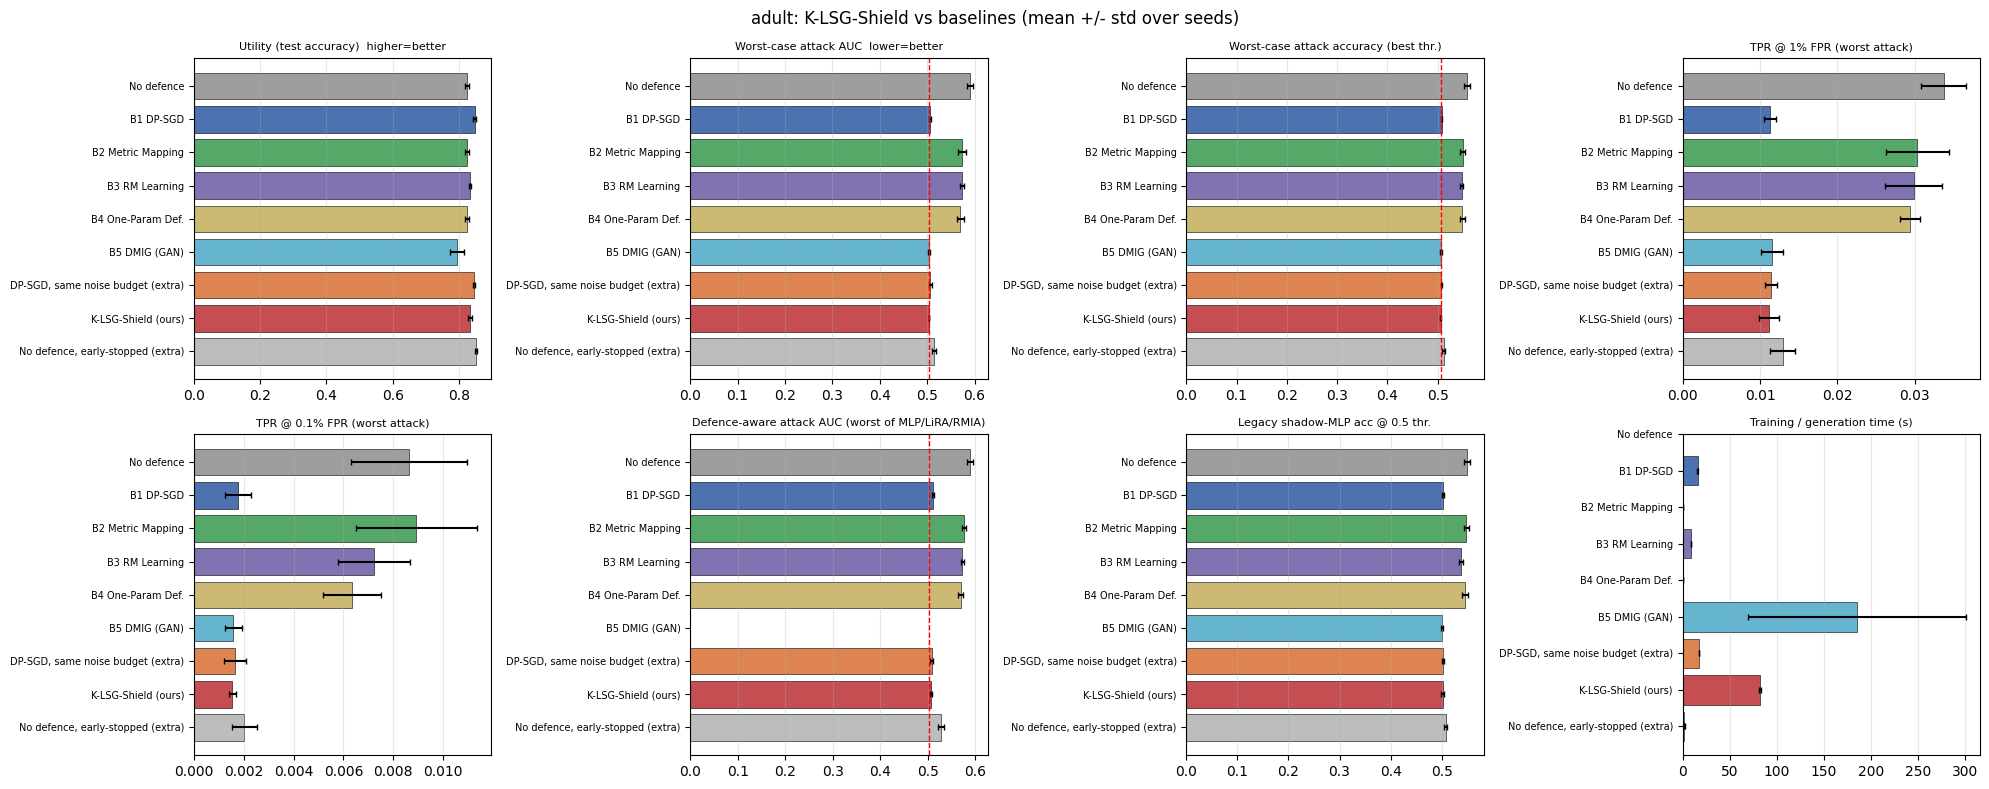

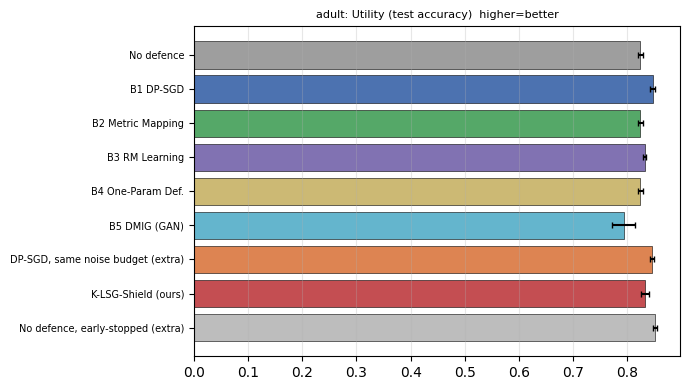

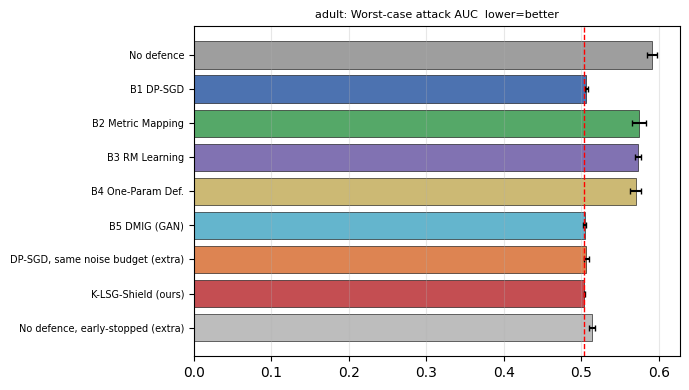

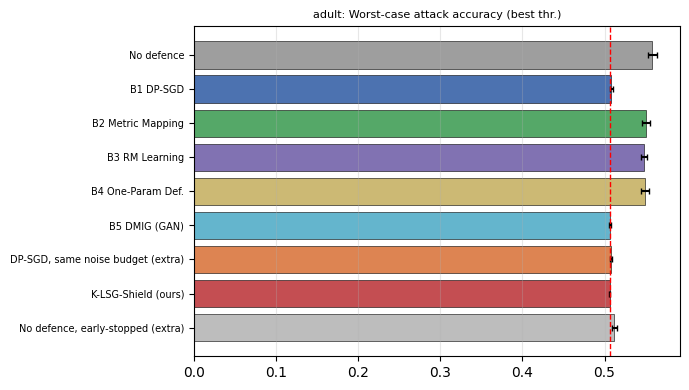

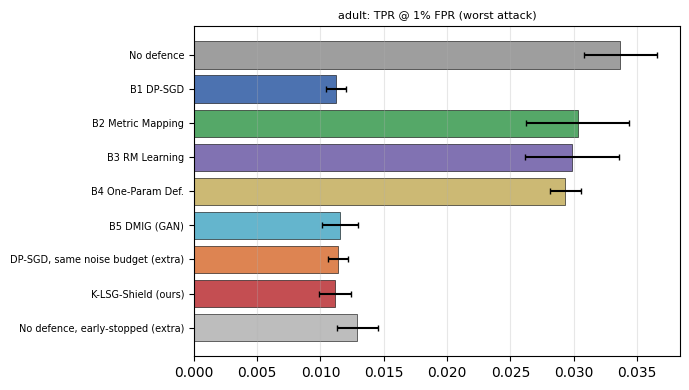

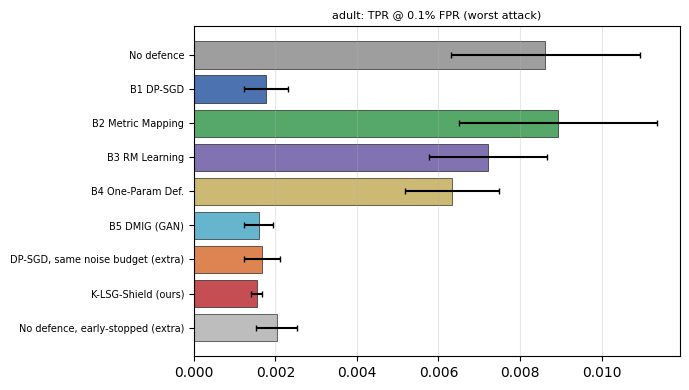

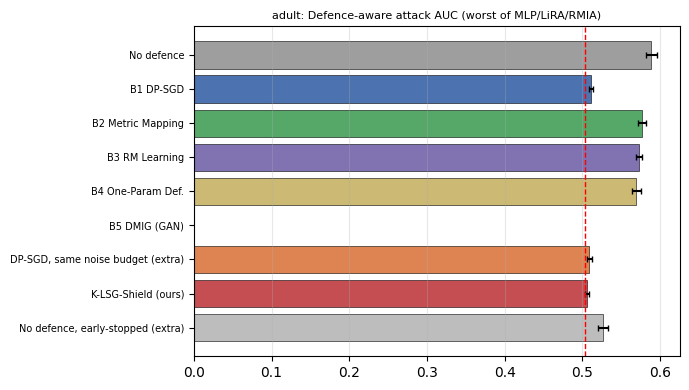

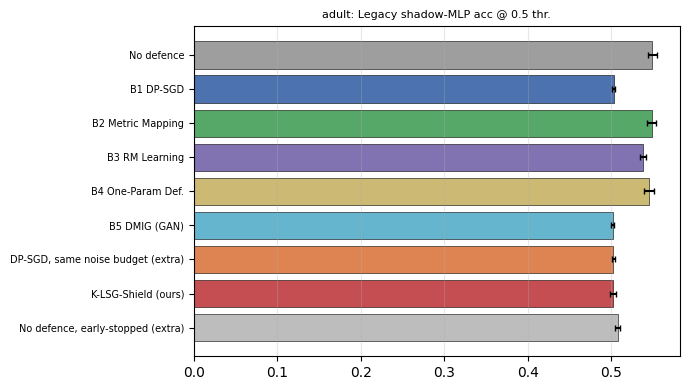

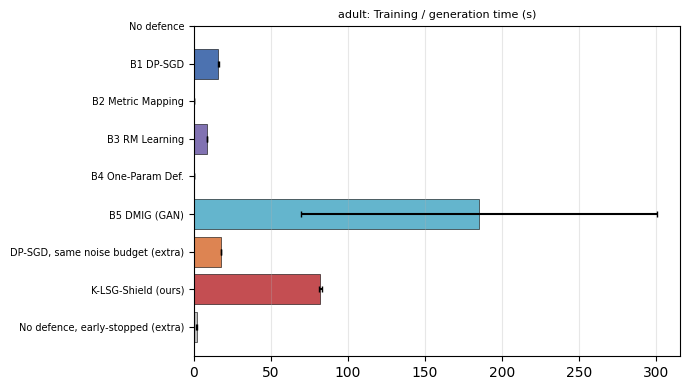

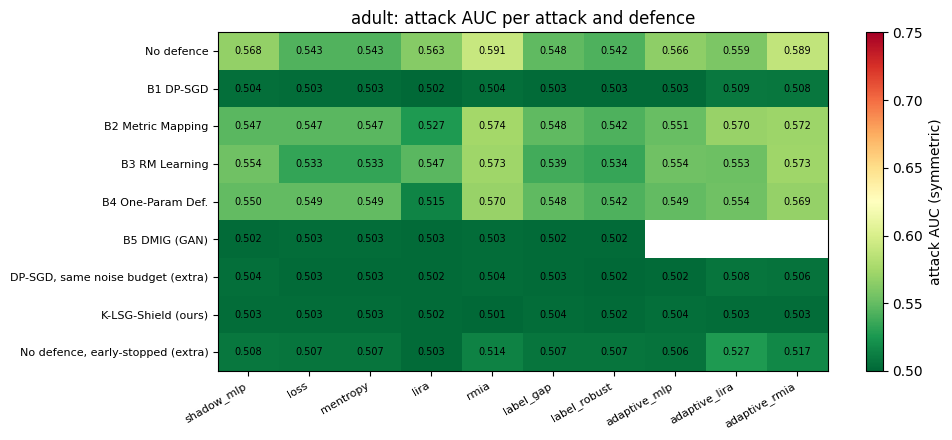

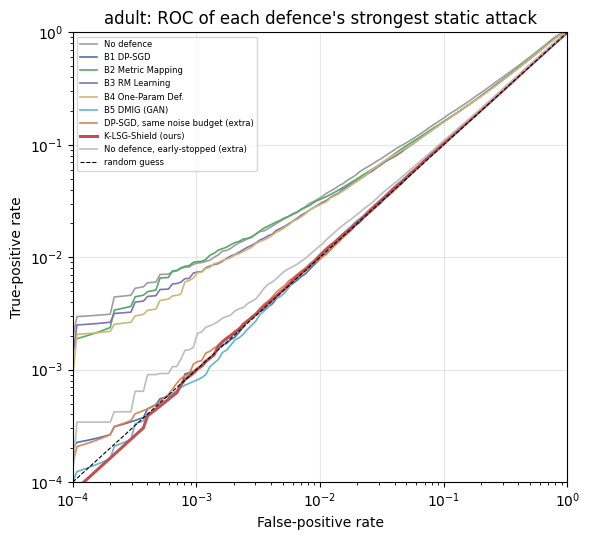

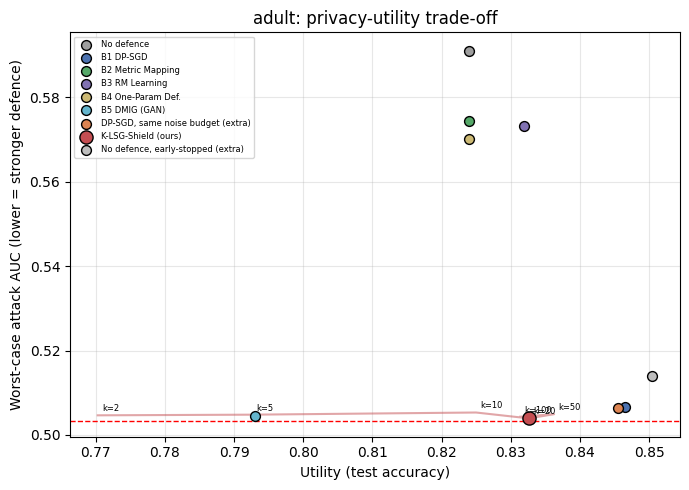

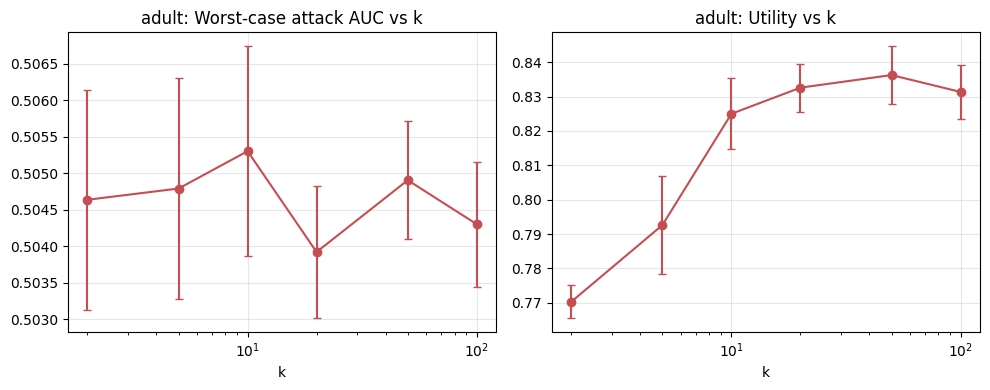

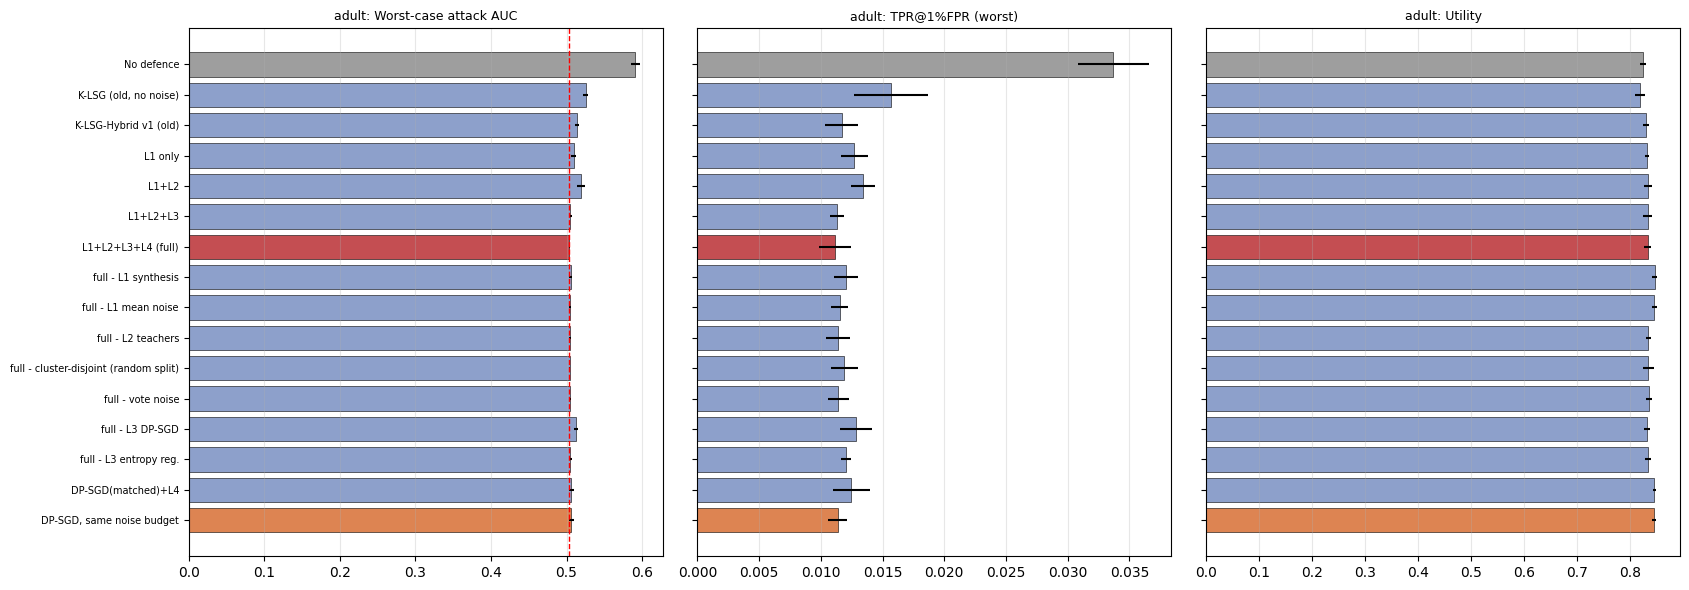

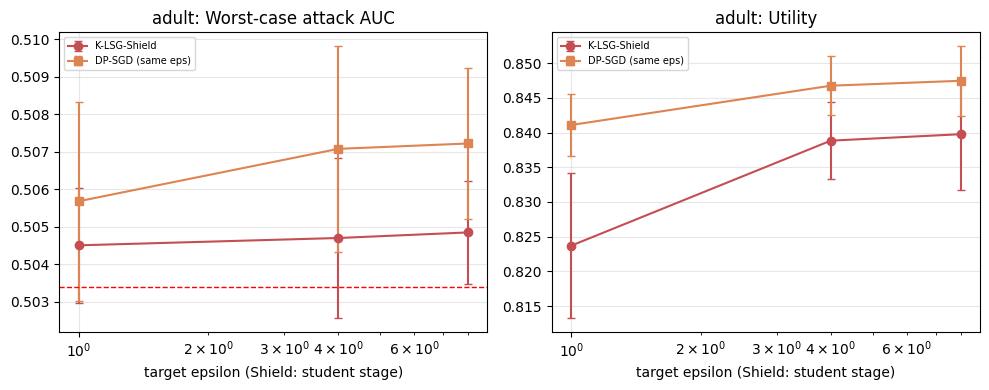

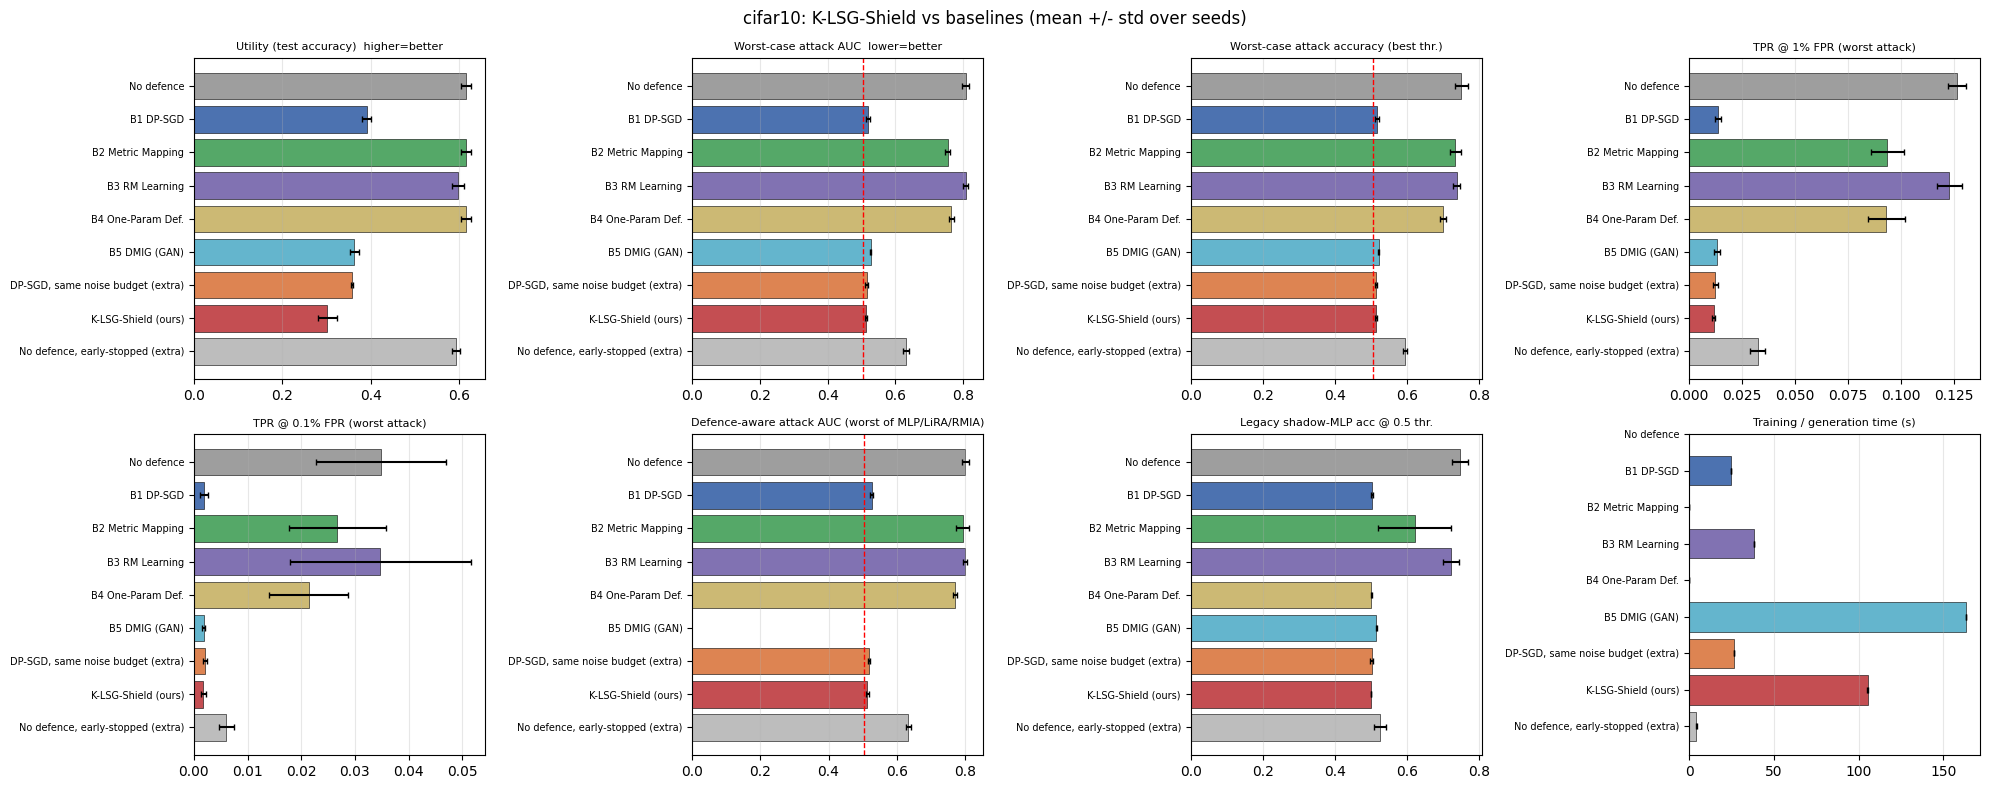

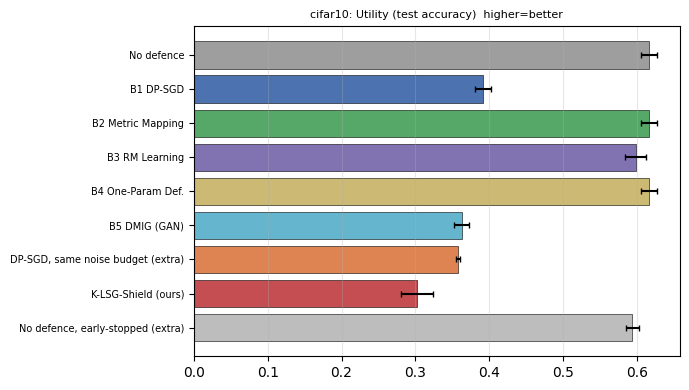

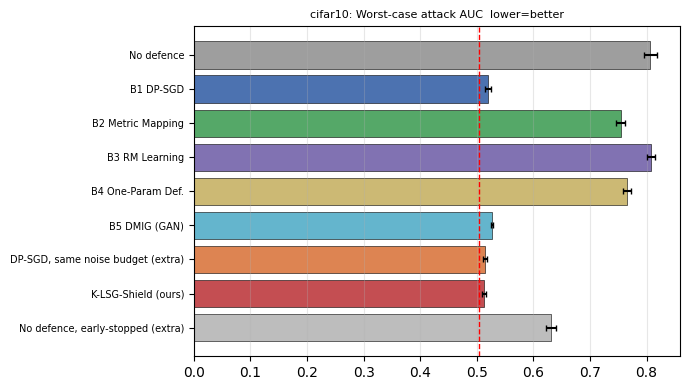

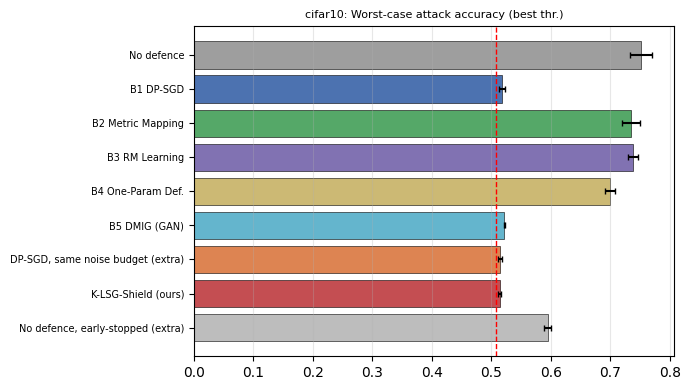

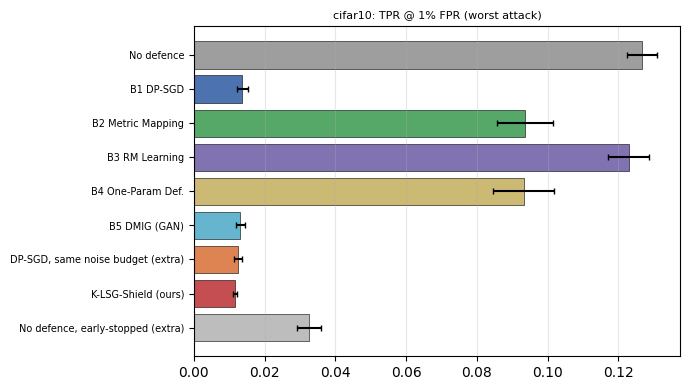

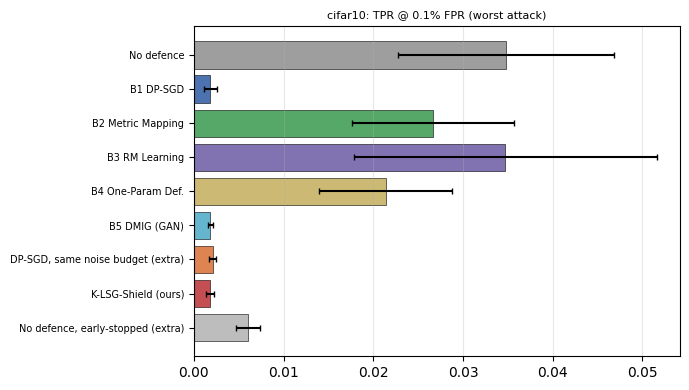

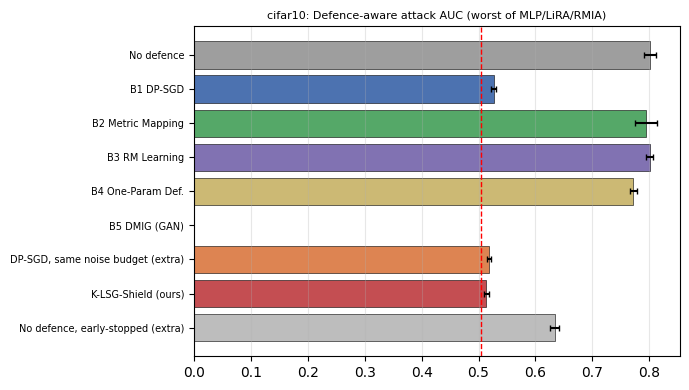

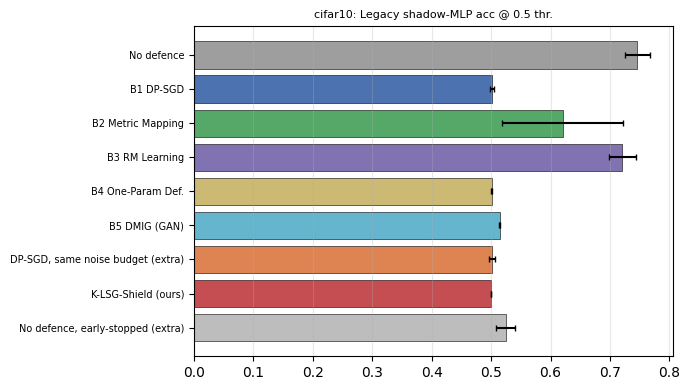

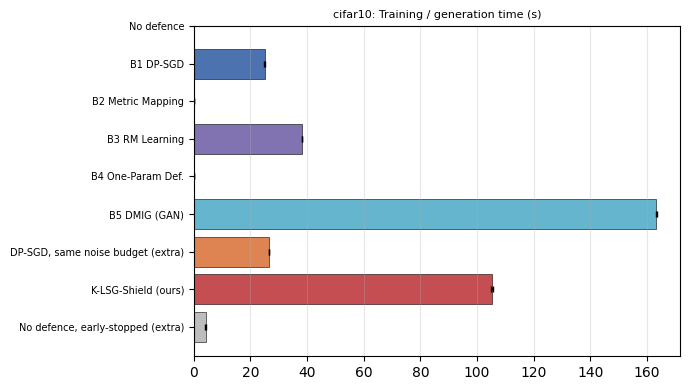

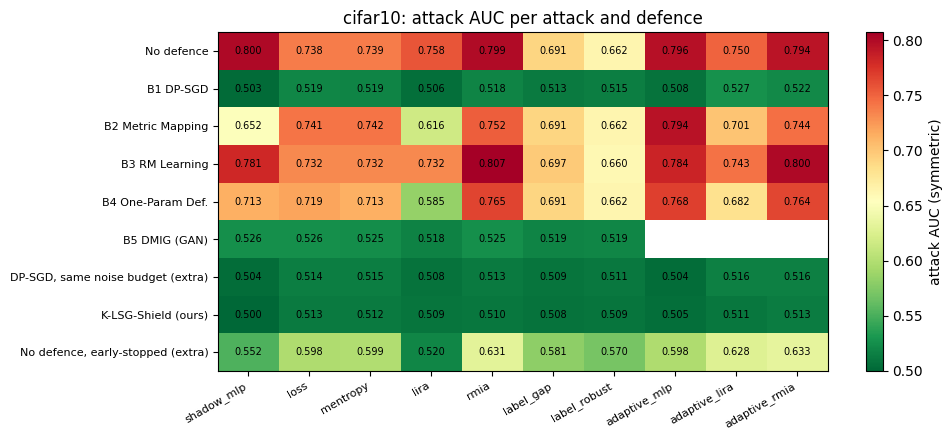

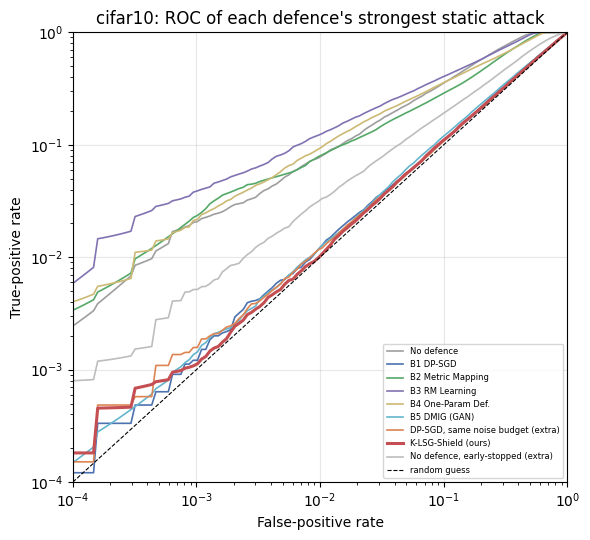

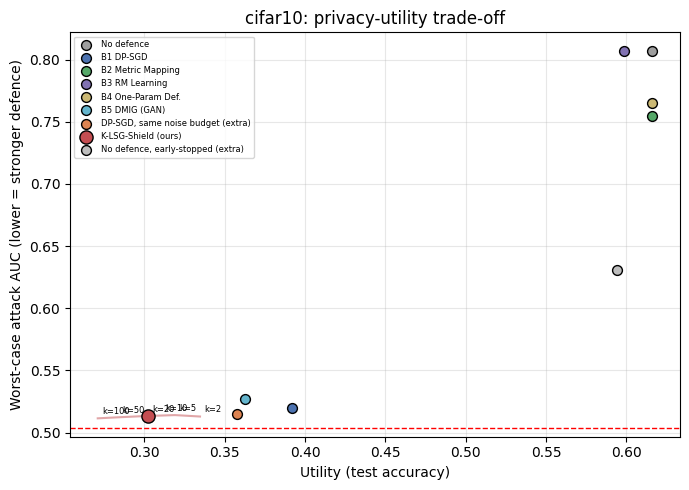

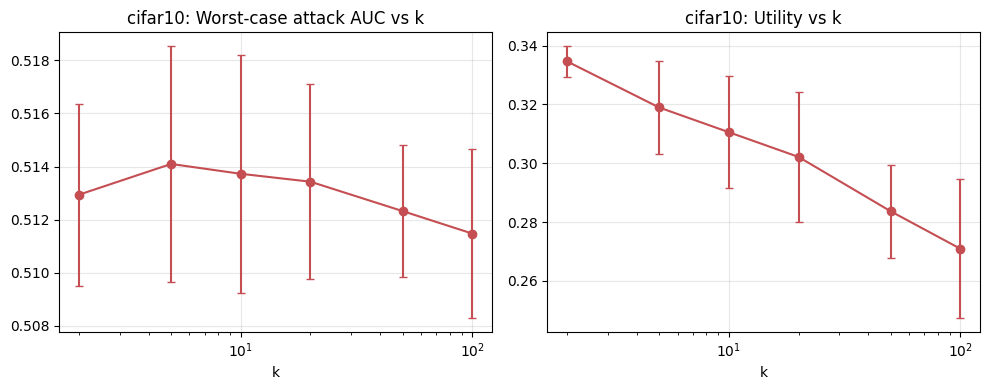

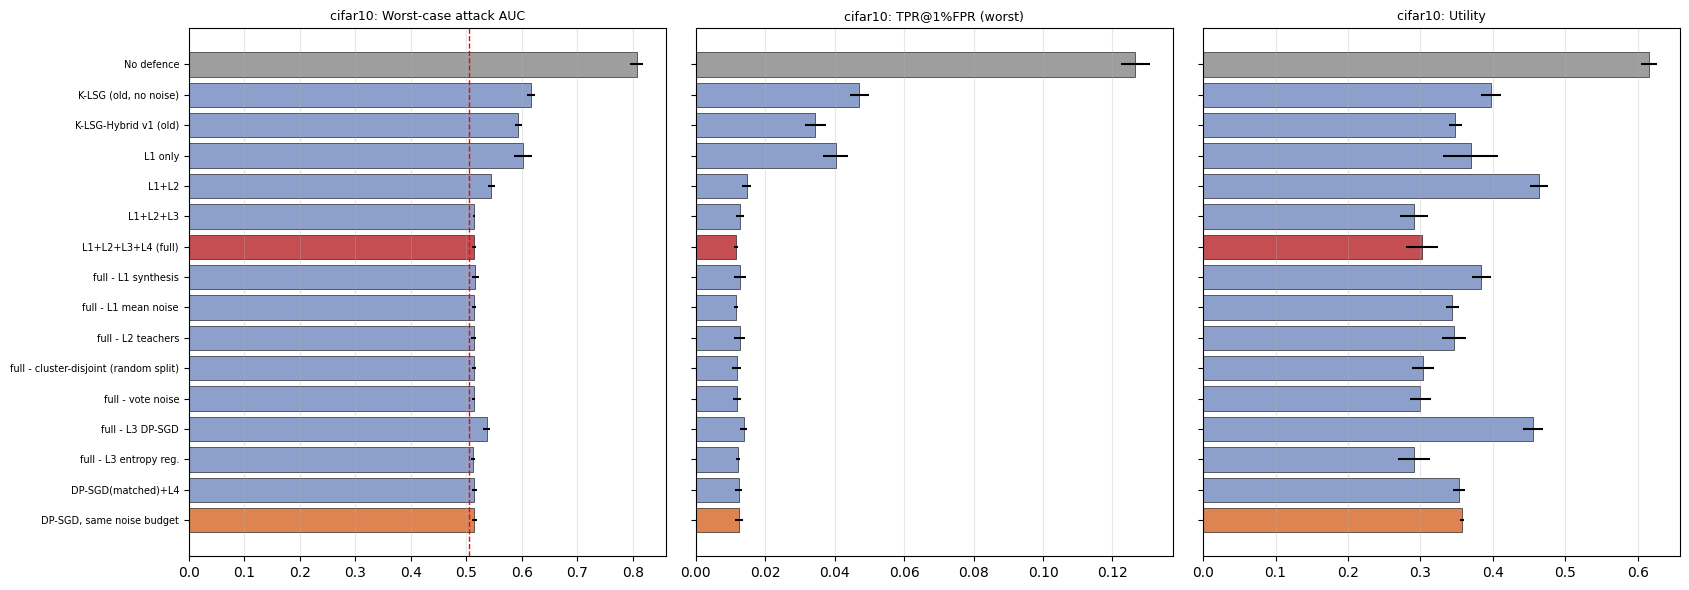

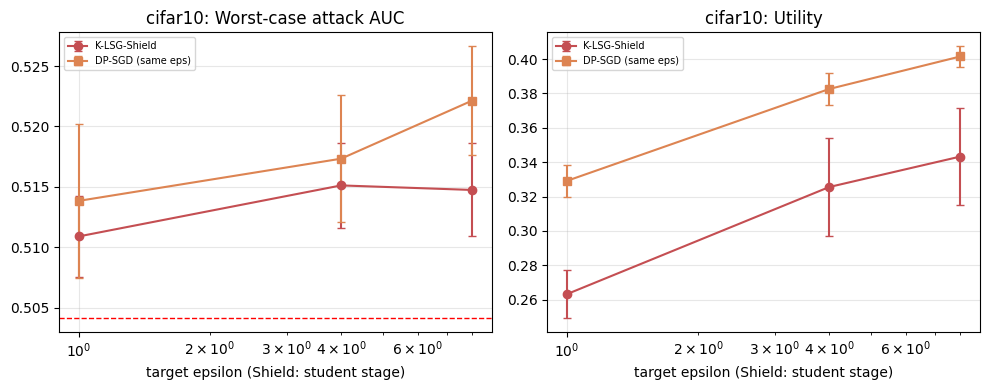


VERDICT  (positive improvement = K-LSG-Shield stronger; tolerance 0.005)

[adult] random-guess AUC floor ~ 0.5034
  vs B1 DP-SGD                      auc_worst: tie / inconclusive (+0.0026), adv_worst: tie / inconclusive (+0.0017), tpr1_worst: tie / inconclusive (+0.0001), tpr01_worst: tie / inconclusive (+0.0002), auc_adaptive: tie / inconclusive (-0.0015), auc_adaptive_worst: tie / inconclusive (+0.0047)
  vs B2 Metric Mapping              auc_worst: SHIELD STRONGER (+0.0704), adv_worst: SHIELD STRONGER (+0.0439), tpr1_worst: SHIELD STRONGER (+0.0192), tpr01_worst: SHIELD STRONGER (+0.0074), auc_adaptive: SHIELD STRONGER (+0.0464), auc_adaptive_worst: SHIELD STRONGER (+0.0703)
  vs B3 RM Learning                 auc_worst: SHIELD STRONGER (+0.0692), adv_worst: SHIELD STRONGER (+0.0414), tpr1_worst: SHIELD STRONGER (+0.0187), tpr01_worst: SHIELD STRONGER (+0.0057), auc_adaptive: SHIELD STRONGER (+0.0497), auc_adaptive_worst: SHIELD STRONGER (+0.0666)
  vs B4 One-Param Def.           

In [2]:
# =====================================================================================
# K-LSG-SHIELD v2 -- ONE CELL, FULLY AUTOMATIC
# Kaggle: Settings -> Accelerator = GPU T4, Internet = ON. Then Save Version -> "Save & Run All (Commit)".
# It installs Opacus, restores earlier progress, runs 5 seeds x {adult, cifar10} (resumable),
# builds all tables/figures/bootstrap, and zips everything to /kaggle/working/K-LSG-Shield_results.zip
# Smoke test (2 min, fake data): set  os.environ["MIA_SMOKE"]="1"  in the CONFIG block below.
# =====================================================================================
import os, sys, subprocess, shutil, glob, time, json, zipfile
from pathlib import Path

# ---------------- CONFIG (change nothing for the final run) ----------------
os.environ.setdefault("MIA_SEEDS", "5")
os.environ.setdefault("MIA_BOOT", "1000")
os.environ.setdefault("MIA_DATASETS", "adult,cifar10")
os.environ.setdefault("MIA_TIME_BUDGET_H", "8.0")
# os.environ["MIA_SMOKE"] = "1"      # <- uncomment ONLY for a quick test with fake data
# ---------------------------------------------------------------------------

try:
    import opacus
    assert opacus.__version__ == "1.6.0"
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "opacus==1.6.0"], check=True)

ON_K = os.path.exists("/kaggle/working")
WORK = Path("/kaggle/working") if ON_K else Path(os.environ.get("MIA_OUT", "results")).resolve().parent
RES = Path("/kaggle/working/results") if ON_K else Path(os.environ.get("MIA_OUT", "results")).resolve()
if os.environ.get("MIA_SMOKE") == "1" and ON_K:
    os.environ.setdefault("MIA_SEEDS", "2")

# ---- restore progress from an earlier session (attach its output as Input data) ----
for sub in ("runs", "scores"):
    (RES / sub).mkdir(parents=True, exist_ok=True)
    for src in glob.glob(f"/kaggle/input/**/{sub}/*", recursive=True):
        dst = RES / sub / Path(src).name
        if os.path.isfile(src) and not dst.exists():
            shutil.copy(src, dst)
print("restored files:", {s: len(list((RES / s).glob('*'))) for s in ("runs", "scores")})

TABS_SRC = r'''import pandas as pd, numpy as np
import os; U=os.environ.get("RES","results/tables")+"/"
A=pd.read_csv(U+"all_results_aggregated.csv")
P=pd.read_csv(U+"shield_vs_baselines_paired.csv")
def r(ds,s): return A[(A.dataset==ds)&(A.setting==s)].iloc[0]
def f(x,sd=None,d=3):
    if pd.isna(x): return "--"
    return f"{x:.{d}f}"+(f"$\\pm${sd:.{d}f}" if sd is not None and not pd.isna(sd) else "")
MAIN=[("no_defence","No defence"),("baseline_dpsgd","B1 DP-SGD"),("baseline_metric_mapping","B2 Metric Mapping"),("baseline_rm_learning","B3 RM Learning"),
      ("baseline_one_param","B4 One-Parameter"),("baseline_dmig_heavy_generator","B5 DMIG"),("ref_dpsgd_matched_eps","DP-SGD ($\\varepsilon{=}2$)"),("k_lsg_shield_k_20","\\textbf{K-LSG-Shield}")]
cols=[("utility","Util.$\\uparrow$"),("auc_worst_static","AUC$_{w}\\downarrow$"),("adv_worst_static","Acc$_{w}\\downarrow$"),("tpr1_worst_static","TPR@1\\%$\\downarrow$"),("tpr01_worst_static","TPR@0.1\\%$\\downarrow$"),("auc_adaptive_worst","AUC$_{ad}\\downarrow$")]
def main_table(ds,dn,lab):
    L=["\\begin{table*}[!t]","\\centering\\small","\\caption{%s: main results (mean$\\pm$std over 5 seeds). AUC$_w$/Acc$_w$ are the worst case over the seven static attacks; AUC$_{ad}$ is the defence-aware adaptive attack. Random-guess floor: AUC $%.3f$, accuracy $%.3f$. Lower is better for every privacy column. Bold marks the nominal best; differences among B1, B5, DP-SGD and K-LSG-Shield are within seed noise.}"%(dn,r(ds,'no_defence').floor_auc,r(ds,'no_defence').floor_adv),
       "\\label{%s}"%lab,"\\begin{tabular}{l"+"c"*len(cols)+"}","\\toprule","Method & "+" & ".join(c for _,c in cols)+" \\\\","\\midrule"]
    best={m:min(r(ds,s)[m+"_mean"] for s,_ in MAIN if not pd.isna(r(ds,s)[m+"_mean"])) for m,_ in cols[1:]}
    for s,l in MAIN:
        x=r(ds,s); cells=[]
        for m,_ in cols:
            v=x[m+"_mean"]; t=f(v,x[m+"_std"])
            if m!="utility" and not pd.isna(v) and abs(v-best[m])<1e-12: t="\\textbf{"+t+"}"
            cells.append(t)
        L.append(l+" & "+" & ".join(cells)+" \\\\")
        if s=="ref_dpsgd_matched_eps": L.append("\\midrule")
    L+=["\\bottomrule","\\end{tabular}","\\end{table*}"]; return "\n".join(L)
AB=[("abl_k_lsg_pure","K-LSG (pure, no noise)"),("abl_v1_hybrid","K-LSG-Hybrid v1"),("abl_c1_L1_only","L1 only"),("abl_c2_L1_L2","L1+L2"),("abl_no_L4_sanitizer","L1+L2+L3 ($=$ full $-$L4)"),("k_lsg_shield_k_20","\\textbf{Full: L1+L2+L3+L4}"),
    ("abl_no_L1_synth","Full $-$ L1 synthesis"),("abl_no_L1_noise","Full $-$ L1 mean noise"),("abl_no_L2_teachers","Full $-$ L2 teachers"),("abl_no_L2_cluster_disjoint","Full $-$ cluster-disjoint (random split)"),("abl_no_L2_vote_noise","Full $-$ L2 vote noise"),
    ("abl_no_L3_dp","Full $-$ L3 DP-SGD"),("abl_no_L3_entropy","Full $-$ L3 entropy reg."),("abl_dpsgd_matched_plus_L4","DP-SGD ($\\varepsilon{=}2$) + L4"),("ref_dpsgd_matched_eps","DP-SGD ($\\varepsilon{=}2$)"),("no_defence","No defence")]
ac=[("utility","Util."),("auc_worst_static","AUC$_w$"),("adv_worst_static","Acc$_w$"),("tpr1_worst_static","TPR@1\\%"),("tpr01_worst_static","TPR@0.1\\%")]
def abl(ds,dn,lab):
    L=["\\begin{table*}[!t]","\\centering\\small","\\caption{%s: ablation of K-LSG-Shield at $k{=}20$, $\\varepsilon{=}2$ (mean$\\pm$std, 5 seeds). Cumulative rows add layers; leave-one-out rows remove one component from the full model.}"%dn,"\\label{%s}"%lab,
       "\\begin{tabular}{l"+"c"*len(ac)+"}","\\toprule","Variant & "+" & ".join(c for _,c in ac)+" \\\\","\\midrule"]
    for i,(s,l) in enumerate(AB):
        x=r(ds,s); L.append(l+" & "+" & ".join(f(x[m+'_mean'],x[m+'_std']) for m,_ in ac)+" \\\\")
        if s in("abl_v1_hybrid","k_lsg_shield_k_20","abl_no_L3_entropy"): L.append("\\midrule")
    L+=["\\bottomrule","\\end{tabular}","\\end{table*}"]; return "\n".join(L)
def pf(p): return "$<$0.001" if p<0.001 else f"{p:.3f}"
def holm(ps):
    ps=np.array(ps); o=np.argsort(ps); m=len(ps); adj=np.empty(m); run=0
    for r_,i in enumerate(o):
        run=max(run,(m-r_)*ps[i]); adj[i]=min(1,run)
    return adj
def paired():
    names={"baseline_dpsgd":"B1","baseline_metric_mapping":"B2","baseline_rm_learning":"B3","baseline_one_param":"B4","baseline_dmig_heavy_generator":"B5","ref_dpsgd_matched_eps":"DP-SGD ($\\varepsilon{=}2$)"}
    rows=[]
    for ds,dn in [("adult","Adult"),("cifar10","CIFAR")]:
        for b,n in names.items():
            for met in ("auc_worst_static","auc_adaptive_worst"):
                d=P[(P.dataset==ds)&(P.baseline==b)&(P.metric==met)]
                if len(d): rows.append((ds,dn,b,n,met,d.iloc[0]))
    adj=holm([r[5].p_value_paired_t for r in rows]); H={(r[0],r[2],r[4]):a for r,a in zip(rows,adj)}
    L=["\\begin{table*}[!t]","\\centering\\small","\\caption{Paired comparison of K-LSG-Shield against each baseline over 5 seeds (paired $t$-test). $\\Delta$ = baseline minus Shield (positive favours Shield); wins = seeds in which Shield is lower; $p$ is the raw value and $p_{H}$ is the Holm-adjusted value over all %d tests in this table. We call a difference clear only when $p_H<0.05$. B5 on Adult Income is shown for completeness, but its training failed (Section~\\ref{sec:results}).}"%len(rows),"\\label{tab:paired}",
       "\\begin{tabular}{llcccccccc}","\\toprule","Data & Baseline & $\\Delta$AUC$_w$ & wins & $p$ & $p_H$ & $\\Delta$AUC$_{ad}$ & $p$ & $p_H$\\\\","\\midrule"]
    for ds,dn in [("adult","Adult"),("cifar10","CIFAR")]:
        for b,n in names.items():
            a=P[(P.dataset==ds)&(P.baseline==b)&(P.metric=="auc_worst_static")].iloc[0]
            d=P[(P.dataset==ds)&(P.baseline==b)&(P.metric=="auc_adaptive_worst")]
            ad=("%+.3f"%d.iloc[0].improvement,pf(d.iloc[0].p_value_paired_t),pf(H[(ds,b,"auc_adaptive_worst")])) if len(d) else ("--","--","--")
            L.append(f"{dn} & {n} & {a.improvement:+.3f} & {int(a.seeds_shield_better)}/3 & {pf(a.p_value_paired_t)} & {pf(H[(ds,b,'auc_worst_static')])} & {ad[0]} & {ad[1]} & {ad[2]}\\\\")
        if ds=="adult": L.append("\\midrule")
    L+=["\\bottomrule","\\end{tabular}","\\end{table*}"]; return "\n".join(L)
S=pd.read_csv(U+"all_results_all_seeds.csv")
def nodp():
    from scipy import stats
    VAR=[("abl_c2_L1_L2","L1+L2"),("abl_no_L3_dp","L1+L2+L4")]
    BL=[("baseline_metric_mapping","B2"),("baseline_rm_learning","B3"),("baseline_one_param","B4")]
    rows=[]
    for ds,dn in [("adult","Adult"),("cifar10","CIFAR-10")]:
        for v,vn in VAR:
            sv=S[(S.dataset==ds)&(S.setting==v)].sort_values("seed").auc_worst_static.values
            for b,bn in BL:
                sb=S[(S.dataset==ds)&(S.setting==b)].sort_values("seed").auc_worst_static.values
                rows.append((ds,dn,v,vn,b,bn,(sb-sv).mean(),int((sb>sv).sum()),stats.ttest_rel(sb,sv).pvalue))
    adj=holm([r_[8] for r_ in rows])
    L=["\\begin{table}[!t]","\\centering\\scriptsize\\setlength{\\tabcolsep}{3pt}","\\caption{Regime without DP: the non-DP variants of K-LSG-Shield (L1+L2+L4 is the full model without L3) against the three non-DP baselines. AUC$_w$ and utility are means over 5 seeds; $\\Delta$ = baseline minus variant; wins = seeds in which the variant is lower; $p_H$ is Holm-adjusted over these 12 tests.}","\\label{tab:nodp}",
       "\\begin{tabular}{lllccc}","\\toprule","Data & Variant (AUC$_w$/Util.) & vs & $\\Delta$AUC$_w$ & wins & $p_H$\\\\","\\midrule"]
    for i,r_ in enumerate(rows):
        ds,dn,v,vn,b,bn,d,w,p=r_
        x=A[(A.dataset==ds)&(A.setting==v)].iloc[0]
        lab=f"{vn} ({x.auc_worst_static_mean:.3f} / {x.utility_mean:.3f})" if bn=="B2" else ""
        L.append(f"{dn if (bn=='B2' and v==VAR[0][0]) else ''} & {lab} & {bn} & {d:+.3f} & {w}/3 & {pf(adj[i])}\\\\")
        if bn=="B4" and i<len(rows)-1: L.append("\\midrule")
    L+=["\\bottomrule","\\end{tabular}","\\end{table}"]; return "\n".join(L)
def sweeps():
    L=["\\begin{table}[!t]","\\centering\\scriptsize","\\caption{Sweep values (mean over 5 seeds): worst-case static AUC / utility. Shield: K-LSG-Shield; DP: DP-SGD on the real private set with the same target $\\varepsilon$ (same student noise budget).}","\\label{tab:sweep}","\\begin{tabular}{lcccc}","\\toprule",
       " & \\multicolumn{2}{c}{Adult} & \\multicolumn{2}{c}{CIFAR-10}\\\\"," & AUC$_w$ & Util. & AUC$_w$ & Util.\\\\","\\midrule"]
    for k in [2,5,10,20,50,100]:
        a,c=r("adult",f"k_lsg_shield_k_{k}"),r("cifar10",f"k_lsg_shield_k_{k}")
        L.append(f"Shield $k{{=}}{k}$ & {a.auc_worst_static_mean:.3f} & {a.utility_mean:.3f} & {c.auc_worst_static_mean:.3f} & {c.utility_mean:.3f}\\\\")
    L.append("\\midrule")
    for e in [1,4,8]:
        for tag,lab in [("sens_eps_","Shield"),("sens_dpsgd_eps_","DP")]:
            a,c=r("adult",f"{tag}{e}"),r("cifar10",f"{tag}{e}")
            L.append(f"{lab} $\\varepsilon{{=}}{e}$ & {a.auc_worst_static_mean:.3f} & {a.utility_mean:.3f} & {c.auc_worst_static_mean:.3f} & {c.utility_mean:.3f}\\\\")
    L+=["\\bottomrule","\\end{tabular}","\\end{table}"]; return "\n".join(L)
T={"MAIN_ADULT":main_table("adult","Adult Income","tab:main_adult"),"MAIN_CIFAR":main_table("cifar10","CIFAR-10","tab:main_cifar"),
   "ABL_ADULT":abl("adult","Adult Income","tab:abl_adult"),"ABL_CIFAR":abl("cifar10","CIFAR-10","tab:abl_cifar"),"PAIRED":paired(),"NODP":nodp(),"SWEEP":sweeps()}
import json; json.dump(T,open(os.environ.get("TABJSON","tables.json"),"w"))
print(T["PAIRED"]); print(A[A.setting=="k_lsg_shield_k_20"][["dataset","wall_time_sec_mean","gen_time_sec_mean"]])
print(A[A.setting=="no_defence"][["dataset","wall_time_sec_mean"]])
'''
FIGS_SRC = r'''import pandas as pd, numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle, FancyArrowPatch, Polygon, Ellipse
import os; U=os.environ.get("RES","results/tables")+"/"
A=pd.read_csv(U+"all_results_aggregated.csv")
import os; O=os.environ.get("FIGDIR","figs")+"/"; os.makedirs(O,exist_ok=True)
plt.rcParams.update({"font.size":8,"font.family":"serif","axes.spines.top":False,"axes.spines.right":False,"savefig.bbox":"tight"})
M=[("no_defence","No defence","#7f7f7f"),("baseline_dpsgd","B1 DP-SGD","#1f77b4"),("baseline_metric_mapping","B2 Metric Map.","#ff7f0e"),
   ("baseline_rm_learning","B3 RM Learn.","#2ca02c"),("baseline_one_param","B4 One-Param.","#9467bd"),("baseline_dmig_heavy_generator","B5 DMIG","#8c564b"),
   ("ref_dpsgd_matched_eps","DP-SGD ($\\varepsilon$=2, same noise)","#17becf"),("k_lsg_shield_k_20","K-LSG-Shield","#d62728")]
DS=[("adult","Adult Income"),("cifar10","CIFAR-10")]
def row(ds,s): return A[(A.dataset==ds)&(A.setting==s)].iloc[0]
# ---------- 1 metric panels
P=[("utility","Utility (accuracy) $\\uparrow$",None),("auc_worst_static","Worst-case static attack AUC $\\downarrow$","floor_auc"),
   ("adv_worst_static","Worst-case attack accuracy $\\downarrow$","floor_adv"),("tpr1_worst_static","TPR@1% FPR $\\downarrow$",None),
   ("tpr01_worst_static","TPR@0.1% FPR $\\downarrow$",None),("auc_adaptive_worst","Adaptive (defence-aware) AUC $\\downarrow$","floor_auc")]
for ds,dn in DS:
    fig,ax=plt.subplots(2,3,figsize=(7.2,4.6))
    for a,(m,t,fl) in zip(ax.flat,P):
        vals,errs,cols,labs=[],[],[],[]
        for s,l,c in M:
            r=row(ds,s); v=r.get(m+"_mean",np.nan)
            vals.append(0 if pd.isna(v) else v); errs.append(0 if pd.isna(v) else r.get(m+"_std",0)); cols.append(c); labs.append(l)
        y=np.arange(len(vals))[::-1]
        a.barh(y,vals,xerr=errs,color=cols,height=.7,error_kw=dict(lw=.7,capsize=1.5))
        if m=="auc_adaptive_worst": a.text(.5,y[5],"n/a",fontsize=6,va="center")
        a.set_yticks(y); a.set_yticklabels(labs if a in ax[:,0] else [""]*len(y)); a.set_title(t,fontsize=8)
        if fl: a.axvline(row(ds,"no_defence")[fl],color="k",ls=":",lw=.9)
        if m not in("utility",): a.set_xlim(left=0 if m.startswith("tpr") else 0.48)
        if m.startswith("tpr") and False: pass
    ax[0,0].set_yticks(np.arange(8)[::-1]); 
    fig.suptitle(f"{dn}: all metrics against all baselines (mean$\\pm$std, 5 seeds; dotted = random-guess floor)",fontsize=8.5)
    fig.tight_layout(); fig.savefig(O+f"fig_metrics_{ds}.pdf"); plt.close(fig)
# ---------- 2 per-attack heatmap
ATT=[("shadow_mlp","Shadow"),("loss","Loss"),("mentropy","M-Ent"),("lira","LiRA"),("rmia","RMIA"),("label_gap","L-Gap"),("label_robust","L-Rob"),("adaptive_mlp","Adapt.")]
fig,ax=plt.subplots(1,2,figsize=(7.2,2.9))
for a,(ds,dn) in zip(ax,DS):
    Z=np.array([[row(ds,s)[f"aucsym__{k}_mean"] for k,_ in ATT] for s,_,_ in M[1:]])
    im=a.imshow(Z,cmap="viridis_r",vmin=.5,vmax=.85 if ds=="cifar10" else .62,aspect="auto")
    a.set_xticks(range(8)); a.set_xticklabels([n for _,n in ATT],rotation=45,ha="right"); a.set_yticks(range(len(M)-1)); a.set_yticklabels([l for _,l,_ in M[1:]] if ds=="adult" else [""]*7)
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]): a.text(j,i,f"{Z[i,j]:.2f}",ha="center",va="center",fontsize=6,color="k" if Z[i,j]<(.68 if ds=="cifar10" else .56) else "w")
    a.set_title(dn,fontsize=8); a.spines[:].set_visible(False)
    plt.colorbar(im,ax=a,fraction=.04,pad=.02)
fig.suptitle("Symmetric attack AUC per attack (rows: defences; B5 has no adaptive entry; random-guess floor $\\approx$0.50)",fontsize=8)
fig.tight_layout(); fig.savefig(O+"fig_heatmap.pdf"); plt.close(fig)
# B5 has NaN adaptive -> handled as nan text
# ---------- 3 ablation
AB=[("abl_k_lsg_pure","K-LSG (old)"),("abl_v1_hybrid","K-LSG-Hybrid v1"),("abl_c1_L1_only","L1"),("abl_c2_L1_L2","L1+L2"),("k_lsg_shield_k_20","Full (L1-L4)"),
    ("abl_no_L1_synth","$-$L1 synthesis"),("abl_no_L1_noise","$-$L1 mean noise"),("abl_no_L2_teachers","$-$L2 teachers"),("abl_no_L2_cluster_disjoint","$-$L2 cluster-disjoint"),
    ("abl_no_L2_vote_noise","$-$L2 vote noise"),("abl_no_L3_dp","$-$L3 DP-SGD"),("abl_no_L3_entropy","$-$L3 entropy reg."),("abl_no_L4_sanitizer","$-$L4 sanitizer"),
    ("abl_dpsgd_matched_plus_L4","DP-SGD+L4"),("ref_dpsgd_matched_eps","DP-SGD ($\\varepsilon$=2)"),("no_defence","No defence")]
fig,ax=plt.subplots(2,2,figsize=(7.2,6.2))
for j,(ds,dn) in enumerate(DS):
    for i,(m,t) in enumerate([("auc_worst_static","Worst-case static AUC $\\downarrow$"),("utility","Utility $\\uparrow$")]):
        a=ax[i,j]; v=[row(ds,s)[m+"_mean"] for s,_ in AB]; e=[row(ds,s)[m+"_std"] for s,_ in AB]
        col=["#d62728" if s=="k_lsg_shield_k_20" else ("#7f7f7f" if s=="no_defence" else "#1f77b4") for s,_ in AB]
        y=np.arange(len(v))[::-1]; a.barh(y,v,xerr=e,color=col,height=.7,error_kw=dict(lw=.6,capsize=1.2))
        a.set_yticks(y); a.set_yticklabels([l for _,l in AB] if j==0 else [""]*len(v),fontsize=6.5); a.set_title(f"{dn}: {t}",fontsize=8)
        if i==0: a.set_xlim(.48,.62 if ds=="adult" else .85); a.axvline(row(ds,"no_defence")["floor_auc"],color="k",ls=":",lw=.9)
        else: a.set_xlim(0 if ds=="cifar10" else .6,None)
fig.tight_layout(); fig.savefig(O+"fig_ablation.pdf"); plt.close(fig)
# ---------- 4 sweeps
fig,ax=plt.subplots(2,2,figsize=(7.2,4.4))
for j,(ds,dn) in enumerate(DS):
    ks=[2,5,10,20,50,100]; nm=lambda k:f"k_lsg_shield_k_{k}"
    a=ax[0,j]; a.errorbar(ks,[row(ds,nm(k))["auc_worst_static_mean"] for k in ks],[row(ds,nm(k))["auc_worst_static_std"] for k in ks],marker="o",color="#d62728",label="AUC worst-case",capsize=2)
    a.axhline(row(ds,"no_defence")["floor_auc"],color="k",ls=":",lw=.9); a.set_xscale("log"); a.set_xlabel("k"); a.set_ylabel("Worst-case AUC"); a.set_title(f"{dn}: k sweep ($\\varepsilon$=2)",fontsize=8)
    b=a.twinx(); b.plot(ks,[row(ds,nm(k))["utility_mean"] for k in ks],marker="s",color="#1f77b4"); b.set_ylabel("Utility",color="#1f77b4"); b.spines["right"].set_visible(True)
    a=ax[1,j]; ep=[1,4,8]
    sh=[row(ds,f"sens_eps_{e}") for e in ep]; dp=[row(ds,f"sens_dpsgd_eps_{e}") for e in ep]
    a.errorbar(ep,[r.auc_worst_static_mean for r in sh],[r.auc_worst_static_std for r in sh],marker="o",color="#d62728",label="K-LSG-Shield",capsize=2)
    a.errorbar(ep,[r.auc_worst_static_mean for r in dp],[r.auc_worst_static_std for r in dp],marker="^",color="#17becf",label="DP-SGD",capsize=2)
    a.axhline(row(ds,"no_defence")["floor_auc"],color="k",ls=":",lw=.9); a.set_xscale("log"); a.set_xticks(ep); a.set_xticklabels(ep); a.set_xlabel("target $\\varepsilon$"); a.set_ylabel("Worst-case AUC"); a.legend(frameon=False,fontsize=7); a.set_title(f"{dn}: $\\varepsilon$ sweep",fontsize=8)
fig.tight_layout(); fig.savefig(O+"fig_sweeps.pdf"); plt.close(fig)
# ---------- 5 privacy-utility scatter
fig,ax=plt.subplots(1,2,figsize=(7.2,2.8))
for a,(ds,dn) in zip(ax,DS):
    for s,l,c in M:
        r=row(ds,s); a.scatter(r.utility_mean,r.auc_worst_static_mean,color=c,s=28,label=l,zorder=3)
    a.axhline(row(ds,"no_defence")["floor_auc"],color="k",ls=":",lw=.9); a.set_xlabel("Utility (accuracy) $\\rightarrow$ better"); a.set_ylabel("Worst-case AUC $\\downarrow$ better"); a.set_title(dn,fontsize=8)
ax[1].legend(frameon=False,fontsize=6,loc="center left",bbox_to_anchor=(1.0,.5))
fig.tight_layout(); fig.savefig(O+"fig_tradeoff.pdf"); plt.close(fig)
# ---------- 5b privacy-accuracy curve
fig,ax=plt.subplots(1,2,figsize=(7.2,3.0))
for a,(ds,dn) in zip(ax,DS):
    for lab,names,c,mk in [("K-LSG-Shield",["sens_eps_1","k_lsg_shield_k_20","sens_eps_4","sens_eps_8"],"#d62728","o"),("DP-SGD",["sens_dpsgd_eps_1","ref_dpsgd_matched_eps","sens_dpsgd_eps_4","sens_dpsgd_eps_8"],"#17becf","^")]:
        R=[row(ds,n) for n in names]
        a.errorbar([r.utility_mean for r in R],[r.auc_worst_static_mean for r in R],xerr=[r.utility_std for r in R],yerr=[r.auc_worst_static_std for r in R],marker=mk,color=c,label=lab,capsize=2,lw=1)
        for e,r in zip([1,2,4,8],R): a.annotate(f"$\\varepsilon$={e}",(r.utility_mean,r.auc_worst_static_mean),textcoords="offset points",xytext=(3,4 if lab=="DP-SGD" else -9),fontsize=6,color=c)
    a.axhline(row(ds,"no_defence")["floor_auc"],color="k",ls=":",lw=.9); a.set_xlabel("Utility (accuracy)"); a.set_ylabel("Worst-case static AUC"); a.set_title(dn,fontsize=8)
ax[0].legend(frameon=False,fontsize=7)
fig.tight_layout(); fig.savefig(O+"fig_curve.pdf"); plt.close(fig)
# ---------- 6 cost
fig,ax=plt.subplots(1,2,figsize=(7.2,2.4))
for a,(ds,dn) in zip(ax,DS):
    v=[0 if pd.isna(row(ds,s)["gen_time_sec_mean"]) else row(ds,s)["gen_time_sec_mean"] for s,_,_ in M]; a.bar(range(len(v)),v,color=[c for *_,c in M]); a.set_xticks(range(len(v))); a.set_xticklabels([l for _,l,_ in M],rotation=60,ha="right",fontsize=6.5); a.set_title(dn+": defence build time per seed (s)",fontsize=8)
fig.tight_layout(); fig.savefig(O+"fig_cost.pdf"); plt.close(fig)

# ---------- architecture
fig=plt.figure(figsize=(7.2,3.3)); ax=fig.add_axes([0,0,1,1]); ax.set_xlim(0,72); ax.set_ylim(0,33); ax.axis("off")
def box(x,y,w,h,c,t=None,fs=7.5,alpha=.18):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.2,rounding_size=1.2",fc=c,ec=c,alpha=alpha,lw=0)); ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.2,rounding_size=1.2",fc="none",ec=c,lw=1.2))
    if t: ax.text(x+w/2,y+h-1.6,t,ha="center",va="center",fontsize=fs,fontweight="bold",color=c)
def arrow(x1,y1,x2,y2,c="#444"): ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle="-|>",mutation_scale=9,color=c,lw=1.2))
def db(x,y,c="#555",s=1):
    ax.add_patch(Rectangle((x-2*s,y-1.6*s),4*s,3.2*s,fc="#ddd",ec=c,lw=.9)); ax.add_patch(Ellipse((x,y+1.6*s),4*s,1.4*s,fc="#eee",ec=c,lw=.9)); ax.add_patch(Ellipse((x,y-1.6*s),4*s,1.4*s,fc="#ddd",ec=c,lw=.9))
def clusters(x,y):
    rng=np.random.default_rng(1)
    for cx,cy,c in [(x-1.6,y+1.4,"#1f77b4"),(x+1.8,y+1.2,"#2ca02c"),(x,y-1.7,"#ff7f0e")]:
        ax.add_patch(Ellipse((cx,cy),3.6,2.8,fc="none",ec=c,lw=1,ls="--")); p=rng.normal(size=(5,2))*.55; ax.scatter(cx+p[:,0],cy+p[:,1],s=3,color=c)
def shield(x,y,c="#d62728"):
    ax.add_patch(Polygon([[x-2,y+2.4],[x+2,y+2.4],[x+2,y-.4],[x,y-2.6],[x-2,y-.4]],fc=c,ec="k",lw=.8,alpha=.9)); ax.plot([x-1,x-.2,x+1.1],[y+.3,y-.6,y+1.4],color="w",lw=1.8)
def net(x,y,c="#333",n=(3,4,2)):
    xs=[x-3,x,x+3]; pts=[]
    for i,m in enumerate(n): pts.append([(xs[i],y+(j-(m-1)/2)*1.5) for j in range(m)])
    for a_,b_ in zip(pts[:-1],pts[1:]):
        for p in a_:
            for q in b_: ax.plot([p[0],q[0]],[p[1],q[1]],color="#999",lw=.4)
    for l in pts:
        for p in l: ax.add_patch(Circle(p,.5,fc=c,ec="none"))
def lock(x,y):
    ax.add_patch(Rectangle((x-1.3,y-1.4),2.6,2),fc="#444") if False else None
    ax.add_patch(Rectangle((x-1.4,y-1.6),2.8,2.2,fc="#444",ec="none")); ax.add_patch(matplotlib.patches.Arc((x,y+.6),1.9,2.2,theta1=0,theta2=180,color="#444",lw=1.2))
def person(x,y,c="#d62728"):
    ax.add_patch(Circle((x,y+1.2),.8,fc=c,ec="none")); ax.add_patch(matplotlib.patches.Wedge((x,y-1.6),1.8,0,180,fc=c,ec="none"))
# input
box(1,6,9,21,"#555"); ax.text(5.5,25,"Private\ndata",ha="center",va="center",fontsize=7,fontweight="bold",color="#555"); db(5.5,15,s=1.4); lock(5.5,9.5)
# L1
box(14,6,14,21,"#1f77b4","L1"); ax.text(21,22.4,"cluster synthesis",ha="center",fontsize=6.3,color="#1f77b4"); clusters(21,16); ax.text(21,10.2,"$\\mathcal{N}(\\mu+\\eta\\,SE,\\ \\Sigma)$",ha="center",fontsize=6.5)
# L2
box(31,6,14,21,"#2ca02c","L2"); ax.text(38,22.4,"noisy teacher votes",ha="center",fontsize=6.3,color="#2ca02c")
for i,(dx,dy) in enumerate([(-3,17),(0,17),(3,17),(-1.5,12.5),(1.5,12.5)]): net(38+dx*0.0+ (dx*1.0 if False else 0),0) if False else None
for dx in (-4,0,4): ax.add_patch(Circle((38+dx,17),1.3,fc="#2ca02c",alpha=.7,ec="none")); ax.text(38+dx,17,"T",ha="center",va="center",fontsize=6,color="w")
for dx in (-4,0,4): ax.add_patch(Circle((38+dx,12.5),1.3,fc="#2ca02c",alpha=.35,ec="none")); ax.text(38+dx,12.5,"T",ha="center",va="center",fontsize=6,color="#2ca02c")
ax.text(38,9.2,"$+\\mathcal{N}(0,\\sigma_v^2)$ votes",ha="center",fontsize=6.5)
# L3
box(48,6,12,21,"#9467bd","L3"); ax.text(54,22.4,"DP-SGD student",ha="center",fontsize=6.3,color="#9467bd"); net(54,15.5,"#9467bd"); ax.text(54,9.5,"clip + noise\n$\\varepsilon$=2",ha="center",va="center",fontsize=6.5)
# L4
box(63,6,8,21,"#d62728","L4"); ax.text(67,22.4,"sanitizer",ha="center",fontsize=6.3,color="#d62728"); shield(67,15.5); ax.text(67,9.5,"rank kept,\nconf. reset",ha="center",va="center",fontsize=6)
for x1,x2 in [(10.4,13.6),(28.4,30.6),(45.4,47.6),(60.4,62.6)]: arrow(x1,16.5,x2,16.5)
# bottom: attacker
ax.text(36,2.6,"Released model API  $\\rightarrow$",ha="right",va="center",fontsize=7); person(41,2.8); ax.text(43.5,2.8,"attacker: 8 attacks, member / non-member?",ha="left",va="center",fontsize=7,color="#d62728")
ax.text(36,31,"K-LSG-Shield: four stacked defences, trained only on private data, released as a prediction API",ha="center",fontsize=8,fontweight="bold")
fig.savefig(O+"fig_architecture.pdf"); fig.savefig(O+"fig_architecture.png",dpi=160); plt.close(fig)
print("ok")
'''

"""
================================================================================
K-LSG-SHIELD v2  --  END-TO-END MEMBERSHIP-INFERENCE DEFENCE BENCHMARK  (Kaggle / local)
Team 22 (Data Privacy capstone)  --  supersedes the K-LSG-Hybrid pipeline
================================================================================
Paste this whole file into ONE Kaggle cell (GPU on, Internet on) or run it as a
script.  Set env MIA_SMOKE=1 for a 2-minute CPU smoke test on synthetic data.

V2 ADDITIONS (answers to the reviewer comments; everything else is unchanged)
  * 5 seeds by default (42..46); per-(dataset, seed) result files, so a crashed or
    split run resumes (MIA_DATASETS=adult / cifar10 in two sessions, then merge).
  * Record-level bootstrap confidence intervals (paired between Shield and each
    baseline) for the worst-case AUC, accuracy and TPR@1% / 0.1% FPR.
  * Holm-corrected paired t-tests (column p_holm in shield_vs_baselines_paired.csv).
  * Defence-aware LiRA and RMIA (adaptive_lira, adaptive_rmia) in addition to the
    adaptive shadow MLP; their statistics come from shadow copies of the FULL
    defence pipeline.  auc_adaptive_worst = max over the three adaptive attacks.
  * Repaired DMIG (B5): per-block categorical handling, auxiliary-classifier loss,
    more epochs and a quality gate (accuracy on the defender reference split must
    beat the majority-class rate; one retry with 2x epochs; flag dmig_ok).
  * Early-stopped undefended reference (no_defence_es, stopped on the defender
    reference split) and train accuracy / train-test gap for every setting.
  * environment.json with library versions, GPU and the Opacus accountant.

WHAT THIS FILE DOES
  1. Re-implements the 5 baselines (B1 DP-SGD, B2 Metric Mapping, B3 RM Learning,
     B4 One-Parameter Defence, B5 DMIG) exactly as in the previous pipeline
     (same hyper-parameters), plus one EXTRA reference: DP-SGD at the same
     epsilon as the proposed model (the "strong DP baseline" recommended by
     arXiv:2404.17399).
  2. Implements the NEW proposed model  K-LSG-Shield  (4 layers, see below).
  3. Evaluates EVERY method against a SUITE of 7 static attacks + 1 defence-aware
     (adaptive) attack, on a BALANCED member / non-member set, and reports the
     worst case over attacks (the number that matters for a defence claim).
  4. Runs a full ablation (cumulative + leave-one-out), a k sweep, an epsilon
     sweep, paired baseline-vs-proposed statistics, all figures and LaTeX tables.

WHY THE OLD EVALUATION HAD TO CHANGE (found in your log / paper, Sec. 3.1)
  * Adult: members (target_train, 10 500) outnumbered non-members (target_holdout,
    5 850), so a trivial "always say member" attacker scores 0.64.  Every Adult
    "attack accuracy" of 0.59-0.65 in the old results is therefore at or below the
    trivial rate and says nothing about defence strength.  Now: balanced sets.
  * CIFAR-10: attack accuracies of 0.39-0.47 (DP-SGD, One-Parameter, DMIG) are
    BELOW 0.5.  That is a calibration artefact of a fixed 0.5 threshold learned on
    undefended shadow models, not extra privacy (the old file's own notes say the
    same about HAMP).  An attacker who knows the defence simply flips/recalibrates.
    Now: symmetric AUC, best-threshold balanced accuracy, TPR@1%/0.1% FPR.
  * B2 (Metric Mapping) and B3 (RM Learning) and the old Hybrid used the
    EVALUATION non-member set (target_holdout) inside their own defence.  Now the
    defender uses a separate `defender_ref` split; the evaluation non-members are
    never touched by any defence.
  * Only one attack (a fixed-threshold shadow MLP) was used.  Evaluation of ML
    privacy defences with weak / non-adaptive attacks is known to be misleading
    (arXiv:2404.17399).  Now: LiRA-style, RMIA-style, loss, modified entropy,
    two label-only attacks, shadow MLP, and a defence-aware shadow MLP.

LITERATURE BASIS FOR THE DESIGN (all read via the web in this session; only the
facts below were taken from the sources -- hyper-parameters are OUR tuning)
  SELENA (Tang et al., USENIX Security 2022, arXiv:2110.08324): Split-AI = ensemble
      of models on random subsets, each query answered ONLY by models that did not
      train on it; self-distillation of the training set through that ensemble.
  HAMP (Chen & Pattabiraman, NDSS 2024, arXiv:2307.01610): high-entropy soft
      labels + entropy regulariser at training time, and a test-time output
      modification that keeps the ranking but replaces confidence values.
  RelaxLoss (Chen et al., ICLR 2022, arXiv:2207.05801): relax the loss target
      (alpha), gradient ascent below alpha, soft-label posterior flattening.
  DMP (Shejwalkar & Houmansadr, AAAI 2021, arXiv:1906.06589): protected model is
      trained only on reference data labelled by an unprotected teacher.
  MIST (Li, Li & Ribeiro, USENIX Security 2024): disjoint-partition models with
      a cross-difference regulariser towards the others' average prediction.
  PATE (Papernot et al., ICLR 2017): noisy aggregation of teacher votes.
  DP-SGD (Abadi et al., 2016; Opacus implementation).
  LiRA (Carlini et al., arXiv:2112.03570) and RMIA (Zarifzadeh et al., ICML 2024,
      arXiv:2312.03262): the strong attacks used for evaluation.
  arXiv:2404.17399 ("Evaluations of Machine Learning Privacy Defenses are
      Misleading"): evaluate with strong adaptive attacks and TPR at low FPR; HAMP,
      RelaxLoss and SELENA were found to leak on worst-case samples, and a
      well-tuned DP-SGD was found to leak >=5.5x less at similar accuracy.
      => the proposed model is built AROUND a real DP-SGD core, not around a
      purely heuristic regulariser.  (Author list of that paper not verified in
      my fetch -- check before citing.)

THE PROPOSED MODEL: K-LSG-SHIELD  (four stacked layers, each targets a different
leak; every layer can be switched off for the ablation)
  L1  K-anonymous noisy synthesis  [data layer]
        k-equivalence clustering (min cluster size >= k) in a model/feature
        embedding, then low-rank+isotropic Gaussian synthesis per (cluster,class)
        with a standard-error-scaled mean perturbation (strength SHIELD_MEAN_NOISE)
        and categorical-aware sampling.  The released model never trains on a real
        record.  (Your own K-LSG, strengthened.)
  L2  Cluster-disjoint self-distillation with noisy votes  [label layer]
        M teachers are trained on REAL data, but the training set is partitioned
        BY k-EQUIVALENCE CLUSTER (all near-duplicates of a record fall in the same
        group) and each synthetic record is labelled only by the teachers that did
        NOT train on its source cluster (out-of-bag, SELENA-style), with Gaussian
        noise added to the vote histogram (PATE-style).  Novelty claim (scoped):
        random Split-AI partitions can place a record's near-duplicates in-bag for
        the teachers that label it; aligning the partition with the k-equivalence
        classes removes that leak.  I did not find this combination in the
        sources reviewed; I cannot claim it is globally first.
  L3  DP-SGD student on soft labels  [training layer]
        The student sees only (synthetic input, noisy soft label), is trained with
        per-sample clipping + Gaussian noise (Opacus) at a target epsilon that is
        tighter than baseline B1, plus a HAMP-style entropy regulariser.
  L4  Rank-preserving output sanitiser  [inference layer]
        The released API keeps the predicted ranking (utility unchanged) but
        replaces the confidence values by a randomly drawn reference vector
        (HAMP-style test-time modification).  Confidence-based attacks see noise.

HONEST LIMITS (put these in the paper's "Limitations" paragraph)
  * No end-to-end (epsilon, delta)-DP guarantee.  The student-stage epsilon printed
    in the results is with respect to the SYNTHETIC set the student trains on, not
    the real records; teacher votes and the synthesis step are not accounted.
    Describe the method as empirically evaluated, DP-core-hardened, not as "DP".
  * L4 randomises confidences, so the API is no longer calibrated.  Label-only
    attacks are NOT stopped by L4; they are in the evaluation suite for that reason.
  * Cost: M teachers + clustering + DP training (see gen_time_sec).  Accepted per
    supervisor: defence strength first, utility second.
  * When a baseline is already at the random-guess floor (e.g. DP-SGD on Adult,
    AUC ~ 0.50) nothing can be "stronger"; the script then reports a TIE with the
    random-floor value, it does not manufacture a win.
================================================================================
"""
# ==============================================================================
# 0. SETUP
# ==============================================================================
import subprocess, sys
try:
    import opacus  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opacus"], check=False)

import os, json, time, math, warnings, random, shutil, itertools
from pathlib import Path
from types import SimpleNamespace
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
SMOKE_TEST = os.environ.get("MIA_SMOKE", "0") == "1"
if SMOKE_TEST:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, roc_curve

BASE_SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ON_KAGGLE = os.path.exists("/kaggle/working")
RESULTS_ROOT = (Path("/kaggle/working/results") if ON_KAGGLE
                else Path(os.environ.get("MIA_OUT", "results")))
TABLES_DIR = RESULTS_ROOT / "tables"
FIGS_DIR = RESULTS_ROOT / "figures"
for _d in (TABLES_DIR, FIGS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

RUNS_DIR = RESULTS_ROOT / "runs"
SCORES_DIR = RESULTS_ROOT / "scores"
for _d in (RUNS_DIR, SCORES_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def write_environment():
    import platform
    import scipy, sklearn
    info = dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__,
                pandas=pd.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__,
                matplotlib=matplotlib.__version__, cuda_available=torch.cuda.is_available(),
                cuda=torch.version.cuda, device=str(DEVICE),
                gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else None))
    try:
        import opacus
        from opacus import PrivacyEngine
        info["opacus"] = opacus.__version__
        import inspect
        info["opacus_default_accountant"] = inspect.signature(PrivacyEngine.__init__).parameters["accountant"].default
    except Exception as e:  # pragma: no cover
        info["opacus"] = f"unavailable ({e})"
    (RESULTS_ROOT / "environment.json").write_text(json.dumps(info, indent=2))
    print("ENVIRONMENT:", json.dumps(info))


write_environment()
print("Environment:", "Kaggle" if ON_KAGGLE else "local", "| Device:", DEVICE,
      "| SMOKE_TEST:", SMOKE_TEST)
print("Results ->", RESULTS_ROOT.resolve())

# ------------------------------------------------------------------------------
# GLOBAL CONFIG  (edit here)
# ------------------------------------------------------------------------------
QUICK_MODE = SMOKE_TEST or os.environ.get("MIA_QUICK", "0") == "1"
N_SEEDS = int(os.environ.get("MIA_SEEDS", "2" if SMOKE_TEST else ("2" if QUICK_MODE else "5")))
SEED_LIST = ([int(x) for x in os.environ["MIA_SEED_LIST"].split(",")]
             if os.environ.get("MIA_SEED_LIST") else None)     # e.g. MIA_SEED_LIST=45,46
FORCE_RERUN = os.environ.get("MIA_FORCE", "0") == "1"
BOOT_B = int(os.environ.get("MIA_BOOT", "50" if SMOKE_TEST else "1000"))   # bootstrap replicates
DATASETS = os.environ.get("MIA_DATASETS", "adult,cifar10").split(",")   # "cifar100" also supported (slower)
K_VALUES = [5, 20] if SMOKE_TEST else [2, 5, 10, 20, 50, 100]
K_PRIMARY = 10 if SMOKE_TEST else 20   # k used for the headline model + ablation
EPS_SWEEP = [1.0, 8.0] if SMOKE_TEST else [1.0, 4.0, 8.0]
COV_RANK = 8

# --- Shield hyper-parameters (privacy-first defaults) -------------------------
SHIELD_DEFAULT = dict(
    k=K_PRIMARY,
    mean_noise=2.0,        # L1: x standard-error noise on each cluster mean (old hybrid: 1.0)
    vote_noise=1.0,        # L2: std of Gaussian noise added to the teacher vote counts
    soft_mix=0.5,          # L2: weight of the noisy-vote distribution vs mean teacher probs
    uniform_mix=0.1,       # L2/L3: mix with uniform (HAMP-style high-entropy targets)
    target_eps=2.0,        # L3: student-stage epsilon (baseline B1 sigma=1.0 gives ~4.7-5.2)
    delta=1e-5,
    clip=1.0,              # L3: per-sample gradient clip
    entropy_reg=0.05,      # L3: HAMP-style entropy regulariser weight (normalised by ln C)
    use_synth=True, use_teachers=True, cluster_disjoint=True,
    use_dp=True, sanitizer=True,
)
SAN_MAXCONF_BINARY = 0.65   # L4: mean max-confidence of the reference vectors (C == 2)
SAN_MAXCONF_MULTI = 0.50    # L4: same for C > 2

# --- Evaluation ---------------------------------------------------------------
STATIC_ATTACKS = ["shadow_mlp", "loss", "mentropy", "lira", "rmia", "label_gap", "label_robust"]
ADAPTIVE_ATTACK = "adaptive_mlp"
ADAPTIVE_ATTACKS = ["adaptive_mlp", "adaptive_lira", "adaptive_rmia"]
ADAPT_METHODS = {"no_defence", "no_defence_es", "baseline_dpsgd", "baseline_metric_mapping",
                 "baseline_rm_learning", "baseline_one_param",
                 "ref_dpsgd_matched_eps", f"k_lsg_shield_k_{K_PRIMARY}"}
ADAPT_DMIG = False          # defence-aware shadows for the GAN baseline cost ~8 min/seed (CIFAR)
BOOT_SETTINGS_GROUPS = {"main", "reference"}   # settings whose raw scores are stored for the bootstrap
RUN_ADAPTIVE = True
RUN_ABLATION = True
RUN_K_SWEEP = True
RUN_EPS_SWEEP = True
RUN_LEGACY_SWEEP = False    # old K-LSG / K-LSG-Hybrid k-sweeps (kept only as ablation points)
TIE_TOL = 0.005             # |difference| below this (AUC / advantage) is called a tie


def make_cfg():
    if SMOKE_TEST:
        return {
            "adult":   dict(sample_size=2400, epochs=6, n_shadow=3, hidden=64, n_teachers=4,
                            adapt_shadows=2, dmig_epochs=3, n_aug=3),
            "cifar10": dict(sample_size=2000, epochs=4, n_shadow=3, hidden=64, n_teachers=4,
                            adapt_shadows=2, dmig_epochs=2, n_aug=3),
        }
    if QUICK_MODE:
        return {
            "adult":    dict(sample_size=12000, epochs=20, n_shadow=8, hidden=128, n_teachers=6,
                             adapt_shadows=2, dmig_epochs=30, n_aug=5),
            "cifar10":  dict(sample_size=10000, epochs=12, n_shadow=6, hidden=256, n_teachers=6,
                             adapt_shadows=2, dmig_epochs=20, n_aug=5),
            "cifar100": dict(sample_size=10000, epochs=12, n_shadow=6, hidden=256, n_teachers=6,
                             adapt_shadows=2, dmig_epochs=20, n_aug=5),
        }
    return {
        "adult":    dict(sample_size=None, epochs=40, n_shadow=16, hidden=128, n_teachers=8,
                         adapt_shadows=4, dmig_epochs=150, n_aug=6),
        "cifar10":  dict(sample_size=30000, epochs=30, n_shadow=12, hidden=256, n_teachers=8,
                         adapt_shadows=4, dmig_epochs=60, n_aug=6),
        "cifar100": dict(sample_size=40000, epochs=30, n_shadow=12, hidden=256, n_teachers=8,
                         adapt_shadows=2, dmig_epochs=40, n_aug=6),
    }


CFG = make_cfg()

# six-way disjoint split of the sampled data (fractions of the sample)
SPLIT_FRACS = dict(target_train=0.22, target_holdout=0.22, defender_ref=0.05,
                   attacker_pop=0.03, true_test=0.10, shadow_pool=0.38)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ==============================================================================
# 1. DATA
# ==============================================================================
def load_adult(sample_size, seed):
    from sklearn.datasets import fetch_openml
    try:
        data = fetch_openml("adult", version=2, as_frame=True, parser="auto")
    except Exception as e:
        raise RuntimeError("Could not download Adult from OpenML. On Kaggle enable "
                           "Notebook Settings -> Internet -> On.") from e
    df = data.frame.dropna()
    y = (df["class"].astype(str).str.contains(">50K")).astype(int).values
    X_df = df.drop(columns=["class"])
    num_cols = X_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
    cat_cols = [c for c in X_df.columns if c not in num_cols]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    X = pre.fit_transform(X_df).astype(np.float32)
    ohe = pre.named_transformers_["cat"]
    cat_blocks, start = [], len(num_cols)
    for categories in ohe.categories_:
        end = start + len(categories)
        cat_blocks.append((start, end)); start = end
    if sample_size is not None and len(y) > sample_size:
        idx, _ = train_test_split(np.arange(len(y)), train_size=sample_size,
                                  stratify=y, random_state=seed)
        X, y = X[idx], y[idx]
    return torch.tensor(X), torch.tensor(y, dtype=torch.long), X.shape[1], 2, cat_blocks


def load_cifar(name, sample_size, seed):
    import torchvision
    import torchvision.transforms as T
    cls = torchvision.datasets.CIFAR10 if name == "cifar10" else torchvision.datasets.CIFAR100
    mean, std = ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)) if name == "cifar10" \
        else ((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762))
    tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
    try:
        tr = cls(root="./data", train=True, download=True, transform=tf)
        te = cls(root="./data", train=False, download=True, transform=tf)
    except Exception as e:
        raise RuntimeError("Could not download CIFAR. On Kaggle enable Internet, or attach "
                           "the cifar dataset and point torchvision at it.") from e
    X = torch.cat([torch.stack([tr[i][0] for i in range(len(tr))]),
                   torch.stack([te[i][0] for i in range(len(te))])], 0)
    y = torch.cat([torch.tensor(tr.targets), torch.tensor(te.targets)], 0)
    rng = np.random.default_rng(seed)
    if sample_size is not None and len(y) > sample_size:
        idx = rng.choice(len(y), size=sample_size, replace=False)
        X, y = X[idx], y[idx]
    return X, y, None, (10 if name == "cifar10" else 100), []


def load_synthetic(ds, n, seed):
    """SMOKE-TEST data only (no downloads): noisy-label data that overfits, so
    membership signal exists and every code path can be exercised."""
    rng = np.random.default_rng(seed)
    if ds == "adult":
        d_num, blocks = 12, [(12, 15), (15, 18)]
        Xn = rng.normal(size=(n, d_num)).astype(np.float32)
        w = rng.normal(size=d_num)
        y = ((Xn @ w + 2.0 * rng.normal(size=n)) > 0).astype(np.int64)
        cats = []
        for (s, e) in blocks:
            c = rng.integers(0, e - s, size=n)
            cats.append(np.eye(e - s, dtype=np.float32)[c])
        X = np.concatenate([Xn] + cats, 1)
        return torch.tensor(X), torch.tensor(y), X.shape[1], 2, blocks
    C = 10
    y = rng.integers(0, C, size=n)
    tmpl = rng.normal(scale=0.6, size=(C, 3, 16, 16)).astype(np.float32)
    X = tmpl[y] + rng.normal(scale=1.0, size=(n, 3, 16, 16)).astype(np.float32)
    flip = rng.random(n) < 0.15
    y = np.where(flip, rng.integers(0, C, size=n), y)
    return torch.tensor(X), torch.tensor(y, dtype=torch.long), None, C, []


def load_dataset(ds, cfg, seed):
    if SMOKE_TEST:
        return load_synthetic(ds, cfg["sample_size"], seed)
    if ds == "adult":
        return load_adult(cfg["sample_size"], seed)
    return load_cifar(ds, cfg["sample_size"], seed)


def six_way_split(X, y, seed):
    """Disjoint, stratified: target_train / target_holdout (evaluation non-members)
    / defender_ref (defender-side validation & reference, never used for
    evaluation) / attacker_pop (public population for RMIA) / true_test (utility)
    / shadow_pool (attacker's shadow models)."""
    n = len(y)
    y_np = y.numpy()
    rest, out, remaining = np.arange(n), {}, 1.0
    names = list(SPLIT_FRACS.keys())
    for i, name in enumerate(names):
        if i == len(names) - 1:
            out[name] = rest
            break
        frac = SPLIT_FRACS[name] / remaining
        try:
            take, rest_new = train_test_split(rest, train_size=frac, random_state=seed + i,
                                              stratify=y_np[rest])
        except ValueError:
            take, rest_new = train_test_split(rest, train_size=frac, random_state=seed + i)
        out[name], rest = take, rest_new
        remaining -= SPLIT_FRACS[name]
    return {k: (X[v], y[v]) for k, v in out.items()}


# ==============================================================================
# 2. MODELS
# ==============================================================================
class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden, num_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden // 2), nn.ReLU(),
                                 nn.Linear(hidden // 2, num_classes))

    def forward(self, x, T=1.0):
        return self.net(x) / T


class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(4))
        self.fc_embed = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU())
        self.fc_out = nn.Linear(256, num_classes)

    def embed(self, x):
        return self.fc_embed(self.conv(x))

    def forward(self, x, T=1.0):
        return self.fc_out(self.embed(x)) / T


def make_model(ctx):
    if ctx.dataset == "adult":
        return TabularMLP(ctx.in_dim, ctx.cfg["hidden"], ctx.num_classes).to(DEVICE)
    return SmallCNN(ctx.num_classes).to(DEVICE)


# ==============================================================================
# 3. TRAINING UTILITIES
# ==============================================================================
def make_loader(X, y, batch_size=128, shuffle=True):
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=shuffle)


def train_standard(model, X, y, epochs, lr=1e-3, batch_size=128):
    t0 = time.time()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, y, batch_size)
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    return model, time.time() - t0


def train_standard_es(model, X, y, Xval, yval, max_epochs, lr=1e-3, batch_size=128, patience=5):
    """Early-stopped undefended training: keep the epoch with the lowest loss on the
    DEFENDER reference split (never the evaluation non-members)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, y, batch_size)
    Xv, yv = Xval.to(DEVICE), yval.to(DEVICE)
    best, best_state, best_ep, bad = float("inf"), None, 0, 0
    for ep in range(max_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); F.cross_entropy(model(xb), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            vl = sum(F.cross_entropy(model(Xv[i:i + 512]), yv[i:i + 512], reduction="sum").item()
                     for i in range(0, len(Xv), 512)) / len(Xv)
        if vl < best - 1e-5:
            best, best_ep, bad = vl, ep + 1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_ep


def soft_ce(logits, soft):
    return -(soft * F.log_softmax(logits, dim=1)).sum(dim=1).mean()


def train_dp(model, X, Y, epochs, soft=False, noise_multiplier=None, target_eps=None,
             delta=1e-5, clip=1.0, lr=1e-3, batch_size=128, entropy_reg=0.0):
    """DP-SGD via Opacus.  Y is hard labels (soft=False) or soft targets (soft=True).
    Pass noise_multiplier (fixed sigma, as baseline B1) OR target_eps (sigma is
    calibrated by the RDP accountant)."""
    from opacus import PrivacyEngine
    t0 = time.time()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, Y, batch_size)
    pe = PrivacyEngine()
    if target_eps is not None:
        model, opt, loader = pe.make_private_with_epsilon(
            module=model, optimizer=opt, data_loader=loader, target_epsilon=target_eps,
            target_delta=delta, epochs=epochs, max_grad_norm=clip)
    else:
        model, opt, loader = pe.make_private(
            module=model, optimizer=opt, data_loader=loader,
            noise_multiplier=noise_multiplier, max_grad_norm=clip)
    max_ent = None
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            if xb.shape[0] == 0:
                continue
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            if soft:
                loss = soft_ce(logits, yb)
                if entropy_reg > 0:
                    if max_ent is None:
                        max_ent = math.log(max(logits.shape[1], 2))
                    pr = F.softmax(logits, dim=1)
                    ent = -(pr * torch.log(pr + 1e-12)).sum(1).mean() / max_ent
                    loss = loss - entropy_reg * ent
            else:
                loss = F.cross_entropy(logits, yb)
            loss.backward()
            opt.step()
    eps = float(pe.get_epsilon(delta=delta))
    sigma = float(getattr(opt, "noise_multiplier", float("nan")))
    plain = model._module if hasattr(model, "_module") else model
    return plain, time.time() - t0, eps, sigma


def train_soft_standard(model, X, soft, epochs, lr=1e-3, batch_size=128, entropy_reg=0.0):
    t0 = time.time()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, soft, batch_size)
    max_ent = math.log(max(soft.shape[1], 2))
    model.train()
    for _ in range(epochs):
        for xb, sb in loader:
            xb, sb = xb.to(DEVICE), sb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            loss = soft_ce(logits, sb)
            if entropy_reg > 0:
                pr = F.softmax(logits, dim=1)
                loss = loss - entropy_reg * (-(pr * torch.log(pr + 1e-12)).sum(1).mean() / max_ent)
            loss.backward()
            opt.step()
    return model, time.time() - t0


def train_rm_learning(model, X, y, X_val, y_val, epochs, lr=1e-3, batch_size=128,
                      T=2.0, target_gap=0.05, lam=1.0):
    """B3 (Zhang et al., 2024): temperature-softened predictions + penalty pulling the
    train/validation loss gap to target_gap.  X_val is the defender's own reference
    split (NOT the evaluation non-members)."""
    t0 = time.time()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, y, batch_size)
    Xv, yv = X_val.to(DEVICE), y_val.to(DEVICE)
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            train_loss = F.cross_entropy(model(xb, T=T), yb)
            val_loss = F.cross_entropy(model(Xv, T=T), yv)
            gap = train_loss - val_loss.detach()
            loss = train_loss + lam * (gap - target_gap).clamp(min=0) ** 2
            loss.backward()
            opt.step()
    return model, time.time() - t0


@torch.no_grad()
def predict_probs(model, X, batch_size=512, T=1.0):
    model.eval()
    outs = []
    for i in range(0, len(X), batch_size):
        outs.append(F.softmax(model(X[i:i + batch_size].to(DEVICE), T=T), dim=1).cpu().numpy())
    return np.concatenate(outs, 0)


# ==============================================================================
# 4. RELEASED SYSTEM  (what the attacker can query)
# ==============================================================================
class Released:
    """The deployed prediction API: a trained model, an optional temperature and an
    optional (possibly stochastic) post-processor on the probability vector."""

    def __init__(self, model, T=1.0, post=None):
        self.model, self.T, self.post = model, T, post

    def probs(self, X):
        p = predict_probs(self.model, X, T=self.T)
        return self.post(p) if self.post is not None else p


# ---- Post-hoc output defences (vectorised re-implementations of B2 / B4) ----------
def metric_mapping_transform(probs, target_entropy, iters=15):
    """B2 (Yadav & Mane, 2025): per-sample temperature search so that the output
    entropy is pulled toward a reference (non-member-like) target entropy."""
    logits = np.log(np.clip(probs, 1e-9, 1 - 1e-9))
    n = len(probs)
    lo, hi = np.full(n, 0.05), np.full(n, 20.0)
    for _ in range(iters):
        mid = (lo + hi) / 2
        z = logits / mid[:, None]; z -= z.max(1, keepdims=True)
        p = np.exp(z); p /= p.sum(1, keepdims=True)
        e = -(p * np.log(p + 1e-12)).sum(1)
        below = e < target_entropy
        lo = np.where(below, mid, lo); hi = np.where(below, hi, mid)
    z = logits / hi[:, None]; z -= z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)


def one_param_defense_transform(probs, rng, epsilon=1.0, m=5):
    """B4 (Ye et al., 2022): exponential mechanism inside per-rank sub-ranges derived
    from the model's own sorted scores (rank order preserved by construction),
    followed by renormalisation."""
    n, C = probs.shape
    order = np.argsort(-probs, axis=1)
    sv = np.take_along_axis(probs, order, axis=1)
    mids = (sv[:, :-1] + sv[:, 1:]) / 2
    upper = np.concatenate([np.ones((n, 1)), mids], 1)
    lower = np.concatenate([mids, np.zeros((n, 1))], 1)
    width = np.maximum(upper - lower, 1e-9)
    cand = lower[:, :, None] + (np.arange(m)[None, None, :] + 0.5) * (width[:, :, None] / m)
    util = -np.abs(cand - sv[:, :, None])
    lg = epsilon * util
    lg -= lg.max(-1, keepdims=True)
    w = np.exp(lg); w /= w.sum(-1, keepdims=True)
    u = rng.random((n, C, 1))
    idx = np.minimum((u > np.cumsum(w, -1)).sum(-1), m - 1)
    new_sorted = np.take_along_axis(cand, idx[:, :, None], axis=2)[:, :, 0]
    out = np.zeros_like(probs)
    np.put_along_axis(out, order, new_sorted, axis=1)
    s = out.sum(1, keepdims=True)
    return np.where(s > 1e-9, out / np.maximum(s, 1e-12), 1.0 / C)


# ---- B5: DMIG conditional-GAN synthetic-data defence (Hu et al., 2022) ------------
class CGeneratorMLP(nn.Module):
    def __init__(self, noise_dim, num_classes, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(noise_dim + num_classes, 256), nn.ReLU(),
                                 nn.Linear(256, 256), nn.ReLU(),
                                 nn.Linear(256, out_dim), nn.Tanh())

    def forward(self, z, y_onehot):
        return self.net(torch.cat([z, y_onehot], 1))


class CDiscriminatorMLP(nn.Module):
    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim + num_classes, 256), nn.LeakyReLU(0.2),
                                 nn.Linear(256, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1))

    def forward(self, x, y_onehot):
        return self.net(torch.cat([x, y_onehot], 1))


class CGeneratorImg(nn.Module):
    def __init__(self, noise_dim, num_classes, img_channels=3, img_size=32):
        super().__init__()
        self.init_size = img_size // 4
        self.label_emb = nn.Embedding(num_classes, noise_dim)
        self.fc = nn.Linear(noise_dim, 128 * self.init_size ** 2)
        self.net = nn.Sequential(
            nn.BatchNorm2d(128), nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, img_channels, 3, padding=1), nn.Tanh())

    def forward(self, z, y):
        x = self.fc(z * self.label_emb(y)).view(-1, 128, self.init_size, self.init_size)
        return self.net(x)


class CDiscriminatorImg(nn.Module):
    def __init__(self, num_classes, img_channels=3, img_size=32):
        super().__init__()
        self.img_size = img_size
        self.label_emb = nn.Embedding(num_classes, img_size * img_size)
        self.net = nn.Sequential(
            nn.Conv2d(img_channels + 1, 64, 3, stride=2, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 3, stride=2, padding=1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 1))

    def forward(self, x, y):
        return self.net(torch.cat([x, self.label_emb(y).view(-1, 1, self.img_size, self.img_size)], 1))


class CGeneratorTab(nn.Module):
    """Tabular generator with per-block categorical handling: numeric columns are
    linear outputs (data are standardised), every one-hot block is a (Gumbel-)softmax
    over its categories, hard one-hot at inference."""

    def __init__(self, noise_dim, num_classes, n_num, blocks):
        super().__init__()
        self.n_num, self.blocks = n_num, blocks
        out_dim = n_num + sum(e - s for s, e in blocks)
        self.net = nn.Sequential(nn.Linear(noise_dim + num_classes, 256), nn.ReLU(), nn.BatchNorm1d(256),
                                 nn.Linear(256, 256), nn.ReLU(), nn.BatchNorm1d(256), nn.Linear(256, out_dim))

    def forward(self, z, y_onehot, tau=0.5):
        h = self.net(torch.cat([z, y_onehot], 1))
        parts, pos = [h[:, :self.n_num]], self.n_num
        for (s_, e_) in self.blocks:
            w = e_ - s_
            lg = h[:, pos:pos + w]; pos += w
            parts.append(F.gumbel_softmax(lg, tau=tau, hard=True) if self.training
                         else F.one_hot(lg.argmax(1), w).float())
        return torch.cat(parts, 1)


class CDiscriminatorTabAC(nn.Module):
    """Conditional discriminator with an auxiliary class head (AC-GAN loss)."""

    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(in_dim, 256), nn.LeakyReLU(0.2), nn.Dropout(0.2),
                                  nn.Linear(256, 256), nn.LeakyReLU(0.2))
        self.adv = nn.Linear(256 + num_classes, 1)
        self.aux = nn.Linear(256, num_classes)

    def forward(self, x, y_onehot):
        h = self.body(x)
        return self.adv(torch.cat([h, y_onehot], 1)), self.aux(h)


def train_dmig_gan(ctx, X, y, epochs, noise_dim=32, batch_size=128):
    bce, C = nn.BCEWithLogitsLoss(), ctx.num_classes
    if ctx.dataset != "adult":
        size = X.shape[-1]
        G = CGeneratorImg(noise_dim, C, X.shape[1], size).to(DEVICE)
        D = CDiscriminatorImg(C, X.shape[1], size).to(DEVICE)
        oG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
        oD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
        xmin, xmax = X.min().item(), X.max().item()
        Xs = 2 * (X.float() - xmin) / (xmax - xmin + 1e-9) - 1
        for _ in range(epochs):
            for xb, yb in make_loader(Xs, y, batch_size):
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                bs = xb.size(0)
                fake = G(torch.randn(bs, noise_dim, device=DEVICE), yb).detach()
                dr, df = D(xb, yb), D(fake, yb)
                dl = bce(dr, torch.ones_like(dr)) + bce(df, torch.zeros_like(df))
                oD.zero_grad(); dl.backward(); oD.step()
                dg = D(G(torch.randn(bs, noise_dim, device=DEVICE), yb), yb)
                gl = bce(dg, torch.ones_like(dg))
                oG.zero_grad(); gl.backward(); oG.step()
        return ("image", G, xmin, xmax, None)
    # ---- repaired tabular DMIG: native-scale features, categorical blocks, AC-GAN loss
    Xf = X.reshape(len(X), -1).float()
    blocks = ctx.cat_blocks
    pos = ctx.n_num
    for (s_, e_) in blocks:                       # data layout must be [numeric | block1 | block2 | ...]
        assert s_ == pos, "unexpected column layout"
        pos = e_
    G = CGeneratorTab(noise_dim, C, ctx.n_num, blocks).to(DEVICE)
    D = CDiscriminatorTabAC(Xf.shape[1], C).to(DEVICE)
    oG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    ce = nn.CrossEntropyLoss()
    for _ in range(epochs):
        G.train(); D.train()
        for xb, yb in make_loader(Xf, y, batch_size):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            bs, yo = xb.size(0), F.one_hot(yb, C).float()
            if bs < 2:
                continue
            fake = G(torch.randn(bs, noise_dim, device=DEVICE), yo).detach()
            (ar, cr), (af, _) = D(xb, yo), D(fake, yo)
            dl = bce(ar, torch.ones_like(ar)) + bce(af, torch.zeros_like(af)) + ce(cr, yb)
            oD.zero_grad(); dl.backward(); oD.step()
            fk = G(torch.randn(bs, noise_dim, device=DEVICE), yo)
            ag, cg = D(fk, yo)
            gl = bce(ag, torch.ones_like(ag)) + ce(cg, yb)
            oG.zero_grad(); gl.backward(); oG.step()
    G.eval()
    return ("tabular", G, 0.0, 1.0, Xf.shape[1])


def dmig_generate_synthetic(ctx, gan_info, n, class_probs, out_shape, noise_dim=32):
    kind, G, xmin, xmax, _ = gan_info
    y_syn = torch.tensor(np.random.choice(ctx.num_classes, size=n, p=class_probs), device=DEVICE)
    with torch.no_grad():
        z = torch.randn(n, noise_dim, device=DEVICE)
        if kind == "image":
            Xs = G(z, y_syn).cpu()
            Xs = (Xs + 1) / 2 * (xmax - xmin) + xmin
        else:
            G.eval()
            Xs = G(z, F.one_hot(y_syn, ctx.num_classes).float()).cpu()
    return Xs.reshape(out_shape), y_syn.cpu()


# ==============================================================================
# 5. K-LSG DATA LAYER (k-anonymous clustering + low-rank Gaussian synthesis)
# ==============================================================================
def k_anon_cluster(X, k, seed, max_rounds=200):
    """k-equivalence clustering: KMeans / MiniBatchKMeans followed by a round-based
    nearest-centroid merge of undersized clusters, so every cluster has >= k points."""
    n = X.shape[0]
    n_clusters = max(1, n // k)
    if n_clusters > 300:
        km = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed, n_init=3,
                             batch_size=min(4096, n)).fit(X)
    else:
        km = KMeans(n_clusters=n_clusters, n_init=10, random_state=seed).fit(X)
    labels = km.labels_.copy()
    for _ in range(max_rounds):
        uniq, counts = np.unique(labels, return_counts=True)
        if len(uniq) == 1 or counts.min() >= k:
            break
        remap_idx = {c: i for i, c in enumerate(uniq)}
        idxs = np.array([remap_idx[l] for l in labels])
        sums = np.zeros((len(uniq), X.shape[1]))
        np.add.at(sums, idxs, X)
        centroids = sums / counts[:, None]
        undersized = counts < k
        nn_ = NearestNeighbors(n_neighbors=min(2, len(uniq))).fit(centroids)
        drained = set()
        for ui in np.argsort(counts):
            if not undersized[ui] or ui in drained:
                continue
            _, nbr = nn_.kneighbors(centroids[ui:ui + 1], n_neighbors=min(2, len(uniq)))
            target = next((j for j in nbr[0] if j != ui and j not in drained), None)
            if target is None:
                continue
            labels[labels == uniq[ui]] = uniq[target]
            drained.add(ui)
    uniq_final = sorted(set(labels.tolist()))
    remap = {o: i for i, o in enumerate(uniq_final)}
    return np.array([remap[l] for l in labels])


def make_cnn_embed_fn(model):
    @torch.no_grad()
    def embed_fn(X):
        model.eval()
        return np.concatenate([model.embed(X[i:i + 512].to(DEVICE)).cpu().numpy()
                               for i in range(0, len(X), 512)], 0).astype(np.float64)
    return embed_fn


def _sample_low_rank_gaussian(pts, n_gen, cov_rank, rng, mean_noise_scale=0.0, cat_blocks=None):
    """Low-rank-plus-isotropic Gaussian sampler per (cluster, class) subset.
    mean_noise_scale > 0 perturbs the sampling mean by mean_noise_scale x its own
    standard error (DP-INSPIRED smoothing, NOT a proven DP mechanism); one-hot
    blocks are drawn from the (smoothed) empirical category distribution."""
    n_pts, d = pts.shape
    true_mean = pts.mean(axis=0)
    mean = true_mean
    if mean_noise_scale > 0:
        se = pts.std(axis=0) / np.sqrt(max(n_pts, 1)) + 1e-8
        mean = true_mean + rng.normal(scale=mean_noise_scale * se, size=d)
    if n_pts <= 1:
        samp = rng.normal(loc=mean, scale=pts.std(axis=0) + 1e-6, size=(n_gen, d))
    else:
        centered = pts - true_mean
        r = min(cov_rank, n_pts - 1, d)
        _, S, Vt = np.linalg.svd(centered, full_matrices=False)
        var_expl = (S[:r] ** 2) / max(n_pts - 1, 1)
        total_var = (S ** 2).sum() / max(n_pts - 1, 1)
        resid = max((total_var - var_expl.sum()) / max(d - r, 1), 1e-6)
        z = rng.normal(size=(n_gen, r))
        samp = (mean[None, :] + (z * np.sqrt(var_expl)[None, :]) @ Vt[:r]
                + rng.normal(scale=np.sqrt(resid), size=(n_gen, d)))
    if cat_blocks:
        for (s, e) in cat_blocks:
            block = pts[:, s:e]
            n_cats = block.shape[1]
            counts = np.bincount(block.argmax(1), minlength=n_cats).astype(np.float64)
            probs = counts / counts.sum() if counts.sum() > 0 else np.ones(n_cats) / n_cats
            if mean_noise_scale > 0:
                a = min(mean_noise_scale / np.sqrt(max(n_pts, 1)), 1.0)
                probs = (1 - a) * probs + a * np.ones(n_cats) / n_cats
            draws = rng.choice(n_cats, size=n_gen, p=probs)
            samp[:, s:e] = 0.0
            samp[np.arange(n_gen), s + draws] = 1.0
    return samp


def compute_clusters(X, k, seed, embed_fn=None):
    emb = embed_fn(X) if embed_fn is not None else X.reshape(len(X), -1).numpy().astype(np.float64)
    return k_anon_cluster(emb, k, seed=seed)


def k_lsg_generate(X, y, labels, seed, cov_rank=COV_RANK, mean_noise_scale=0.0, cat_blocks=None):
    """Synthesise one synthetic record per real record, inside each (cluster, class)
    subset.  Returns the synthetic data, its class labels and the CLUSTER ID of the
    source cluster of every synthetic record (needed by the cluster-disjoint L2)."""
    rng = np.random.default_rng(seed)
    Xn, yn = X.reshape(len(X), -1).numpy().astype(np.float64), y.numpy()
    Xs, ys, cs = [], [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        for cls in np.unique(yn[idx]):
            cidx = idx[yn[idx] == cls]
            samp = _sample_low_rank_gaussian(Xn[cidx], len(cidx), cov_rank, rng,
                                             mean_noise_scale=mean_noise_scale,
                                             cat_blocks=cat_blocks)
            Xs.append(samp); ys.append(np.full(len(cidx), cls)); cs.append(np.full(len(cidx), c))
    Xs = np.concatenate(Xs).astype(np.float32)
    shape = (len(Xs),) + tuple(X.shape[1:])
    sizes = np.bincount(labels)
    stats = {"cluster_num_clusters": int(len(sizes)), "cluster_min_cluster_size": int(sizes.min()),
             "cluster_mean_cluster_size": float(sizes.mean()), "cluster_max_cluster_size": int(sizes.max())}
    return (torch.tensor(Xs).reshape(shape), torch.tensor(np.concatenate(ys), dtype=torch.long),
            np.concatenate(cs), stats)


# ==============================================================================
# 6. K-LSG-SHIELD  (proposed model)
# ==============================================================================
class RankPreservingSanitizer:
    """L4. Keeps the predicted ranking of the classes (so top-k labels / utility are
    unchanged) and replaces the confidence values with a randomly drawn reference
    vector (HAMP-style test-time modification; reference vectors come from the
    student's own outputs on random-noise inputs, flattened by a temperature chosen
    so that the mean max-confidence equals the target)."""

    def __init__(self, ref_sorted, seed):
        self.ref, self.rng = ref_sorted, np.random.default_rng(seed)

    def __call__(self, probs):
        n = probs.shape[0]
        order = np.argsort(-probs, axis=1)
        r = self.ref[self.rng.integers(0, len(self.ref), size=n)]
        out = np.empty_like(r)
        np.put_along_axis(out, order, r, axis=1)
        return out


@torch.no_grad()
def fit_sanitizer(model, ctx, seed, n_ref=2000):
    g = torch.Generator().manual_seed(seed)
    shape = (n_ref, ctx.in_dim) if ctx.dataset == "adult" else (n_ref, 3) + tuple(ctx.img_shape)
    Xr = torch.randn(shape, generator=g)
    model.eval()
    logits = torch.cat([model(Xr[i:i + 512].to(DEVICE)).cpu() for i in range(0, n_ref, 512)], 0)
    target = SAN_MAXCONF_BINARY if ctx.num_classes == 2 else SAN_MAXCONF_MULTI
    lo, hi = -4.0, 4.0                                    # bisection on log-temperature
    for _ in range(40):
        mid = (lo + hi) / 2
        mc = F.softmax(logits / math.exp(mid), 1).max(1).values.mean().item()
        lo, hi = (mid, hi) if mc > target else (lo, mid)  # larger T -> flatter -> lower mc
    p = F.softmax(logits / math.exp((lo + hi) / 2), 1).numpy()
    return RankPreservingSanitizer(-np.sort(-p, axis=1), seed)


def _teacher_probs(teachers, X):
    return np.stack([predict_probs(t, X) for t in teachers], 0)          # (M, n, C)


def _get_teachers(ctx, Xtr, ytr, labels, params, seed, cache):
    """Cluster-disjoint (or random) partition of the REAL training set into M groups;
    teacher j trains on the groups in S_j = {j, j+1, ..., j+M/2-1} (mod M), so every
    group is out-of-bag for exactly M/2 teachers."""
    M = ctx.cfg["n_teachers"]
    key = ("teachers", params["k"], params["cluster_disjoint"], M)
    if key in cache:
        return cache[key]
    _t0 = time.time()
    rng = np.random.default_rng(seed + 7)
    n_cl = int(labels.max()) + 1
    group_of_cluster = rng.permutation(n_cl) % M
    g_real = (group_of_cluster[labels] if params["cluster_disjoint"]
              else rng.integers(0, M, size=len(ytr)))
    inbag = np.zeros((M, M), dtype=bool)
    for j in range(M):
        for t in range(M // 2):
            inbag[j, (j + t) % M] = True
    teachers = []
    for j in range(M):
        idx = np.where(inbag[j][g_real])[0]
        t, _ = train_standard(make_model(ctx), Xtr[idx], ytr[idx], ctx.cfg["epochs"])
        teachers.append(t)
    cache[key] = (teachers, g_real, group_of_cluster, inbag)
    cache[("time",) + key] = time.time() - _t0
    return cache[key]


def train_shield(ctx, Xtr, ytr, seed, params=None, embed_fn=None, cache=None):
    """Train the four-layer K-LSG-Shield on the private set (Xtr, ytr).  Returns a
    Released system and an info dict.  `cache` shares clusters / synthetic data /
    teachers between ablation variants that use identical upstream settings."""
    t0 = time.time()
    p = {**SHIELD_DEFAULT, **(params or {})}
    cache = {} if cache is None else cache
    rng = np.random.default_rng(seed + 11)
    C, k = ctx.num_classes, p["k"]
    info = {"k": k}

    # ---- clustering (needed by L1 and by the cluster-disjoint partition of L2) ----
    shared = 0.0       # time of cached upstream stages, so cost is reported in full even on cache hits
    ckey = ("clusters", k)
    if ckey not in cache:
        _t = time.time()
        cache[ckey] = compute_clusters(Xtr, k, seed, embed_fn)
        cache[("time",) + ckey] = time.time() - _t
    shared += cache[("time",) + ckey]
    labels = cache[ckey]

    # ---- L1: k-anonymous noisy synthesis ------------------------------------------
    if p["use_synth"]:
        skey = ("synth", k, p["mean_noise"])
        if skey not in cache:
            _t = time.time()
            cache[skey] = k_lsg_generate(Xtr, ytr, labels, seed, mean_noise_scale=p["mean_noise"],
                                         cat_blocks=ctx.cat_blocks)
            cache[("time",) + skey] = time.time() - _t
        shared += cache[("time",) + skey]
        Xs, ys, cl_syn, stats = cache[skey]
        info.update(stats)
    else:
        Xs, ys, cl_syn = Xtr, ytr, labels

    # ---- L2: cluster-disjoint self-distillation with noisy votes --------------------
    if p["use_teachers"]:
        teachers, g_real, goc, inbag = _get_teachers(ctx, Xtr, ytr, labels, p, seed, cache)
        shared += cache[("time", "teachers", p["k"], p["cluster_disjoint"], ctx.cfg["n_teachers"])]
        M = len(teachers)
        if p["use_synth"]:
            g_syn = goc[cl_syn] if p["cluster_disjoint"] else rng.integers(0, M, size=len(ys))
        else:
            g_syn = g_real
        P = _teacher_probs(teachers, Xs)                                   # (M, n, C)
        oob = ~inbag[:, g_syn]                                             # (M, n)
        n = P.shape[1]
        n_oob = np.maximum(oob.sum(0), 1)
        mean_prob = (P * oob[:, :, None]).sum(0) / n_oob[:, None]
        votes = np.zeros((n, C))
        pred = P.argmax(-1)
        for j in range(M):
            votes[np.arange(n), pred[j]] += oob[j]
        if p["vote_noise"] > 0:
            votes = votes + rng.normal(scale=p["vote_noise"], size=votes.shape)
        votes = np.clip(votes, 0, None)
        vs = votes.sum(1, keepdims=True)
        noisy = np.where(vs > 0, votes / np.maximum(vs, 1e-12), 1.0 / C)
        soft = p["soft_mix"] * noisy + (1 - p["soft_mix"]) * mean_prob
        info["teacher_label_agreement"] = float((soft.argmax(1) == ys.numpy()).mean())
    else:
        soft = np.eye(C)[ys.numpy()]
    soft = (1 - p["uniform_mix"]) * soft + p["uniform_mix"] / C
    soft = torch.tensor(soft / soft.sum(1, keepdims=True), dtype=torch.float32)

    # ---- L3: student (DP-SGD on soft labels) -----------------------------------------
    student = make_model(ctx)
    if p["use_dp"]:
        student, _, eps, sigma = train_dp(student, Xs, soft, ctx.cfg["epochs"], soft=True,
                                          target_eps=p["target_eps"], delta=p["delta"],
                                          clip=p["clip"], entropy_reg=p["entropy_reg"])
        info.update({"epsilon_student_stage": eps, "noise_multiplier": sigma})
    else:
        student, _ = train_soft_standard(student, Xs, soft, ctx.cfg["epochs"],
                                         entropy_reg=p["entropy_reg"])

    # ---- L4: rank-preserving sanitiser --------------------------------------------------
    post = fit_sanitizer(student, ctx, seed) if p["sanitizer"] else None
    return Released(student, post=post), {**info, "gen_time_sec": time.time() - t0 + shared}


# ==============================================================================
# 7. ATTACK SUITE
# ==============================================================================
def attack_features(P, y):
    """Feature vector used by the MLP attacks (shadow and defence-aware)."""
    n, C = P.shape
    py = np.clip(P[np.arange(n), y], 1e-12, 1.0)
    top = -np.sort(-P, axis=1)
    margin = top[:, 0] - top[:, 1]
    ent = -np.sum(P * np.log(P + 1e-12), axis=1)
    phi = np.log(np.clip(py, 1e-9, 1 - 1e-9)) - np.log(np.clip(1 - py, 1e-9, None))
    correct = (P.argmax(1) == y).astype(np.float64)
    return np.concatenate([top[:, :1], ent[:, None], -np.log(py)[:, None], margin[:, None],
                           py[:, None], phi[:, None], correct[:, None], top[:, :min(C, 10)]], 1)


class MLPAttack:
    def __init__(self, epochs=30):
        self.epochs, self.model = epochs, None

    def fit(self, feats, labels):
        self.mu, self.sd = feats.mean(0), feats.std(0) + 1e-6
        Xf = torch.tensor((feats - self.mu) / self.sd, dtype=torch.float32)
        yf = torch.tensor(labels, dtype=torch.long)
        self.model = nn.Sequential(nn.Linear(Xf.shape[1], 64), nn.ReLU(), nn.Linear(64, 32),
                                   nn.ReLU(), nn.Linear(32, 2)).to(DEVICE)
        train_standard(self.model, Xf, yf, self.epochs)
        return self

    @torch.no_grad()
    def score(self, feats):
        self.model.eval()
        x = torch.tensor((feats - self.mu) / self.sd, dtype=torch.float32).to(DEVICE)
        return F.softmax(self.model(x), 1)[:, 1].cpu().numpy()


def _tpr_at(fpr, tpr, target):
    return float(tpr[max(np.searchsorted(fpr, target, side="right") - 1, 0)])


def attack_metrics(lab, sc):
    """Symmetric (defence-aware) metrics: an attacker who knows the defence may flip
    the score, so every number is the better of the two orientations."""
    sc = np.asarray(sc, dtype=np.float64)
    if np.ptp(sc) < 1e-12:
        return dict(auc=0.5, auc_sym=0.5, adv_acc=0.5, tpr1=0.01, tpr01=0.001, flipped=False)
    auc = float(roc_auc_score(lab, sc))
    f1, t1, _ = roc_curve(lab, sc)
    f2, t2, _ = roc_curve(lab, -sc)
    adv = max(float((t1 - f1).max()), float((t2 - f2).max()))
    return dict(auc=auc, auc_sym=max(auc, 1 - auc), adv_acc=0.5 + 0.5 * adv,
                tpr1=max(_tpr_at(f1, t1, 0.01), _tpr_at(f2, t2, 0.01)),
                tpr01=max(_tpr_at(f1, t1, 0.001), _tpr_at(f2, t2, 0.001)), flipped=auc < 0.5)


def roc_on_grid(lab, sc, grid):
    auc = roc_auc_score(lab, sc)
    f, t, _ = roc_curve(lab, sc if auc >= 0.5 else -sc)
    return np.interp(grid, f, t)


def random_floor(n_each, reps=30, seed=0):
    rng = np.random.default_rng(seed)
    lab = np.r_[np.ones(n_each), np.zeros(n_each)]
    ms = [attack_metrics(lab, rng.random(2 * n_each)) for _ in range(reps)]
    return {k: float(np.mean([m[k] for m in ms])) for k in ("auc_sym", "adv_acc", "tpr1", "tpr01")}


def _stable_phi(P, y):
    py = np.clip(P[np.arange(len(y)), y].astype(np.float64), 1e-9, 1 - 1e-9)
    return np.log(py) - np.log(np.clip(1 - py, 1e-9, None)), py


def build_attack_kit(ctx, split, seed):
    """Attacker side.  Trains undefended shadow models (same size as the target's
    training set, on the attacker's shadow pool) and caches everything the static
    attacks need: the MLP attack, per-example OUT statistics for LiRA / RMIA."""
    rng = np.random.default_rng(seed + 5)
    Xtr, ytr = split["target_train"]
    Xho, yho = split["target_holdout"]
    Xp, yp = split["shadow_pool"]
    Xpop, ypop = split["attacker_pop"]
    n_e = min(len(ytr), len(yho))
    mi, ni = rng.choice(len(ytr), n_e, replace=False), rng.choice(len(yho), n_e, replace=False)
    Xe = torch.cat([Xtr[mi], Xho[ni]], 0)
    ye = torch.cat([ytr[mi], yho[ni]], 0).numpy()
    lab = np.r_[np.ones(n_e), np.zeros(n_e)]
    S, n_in = ctx.cfg["n_shadow"], min(len(ytr), len(yp) - 1)
    feats, flabs, phis, pes, pzs = [], [], [], [], []
    for s in range(S):
        perm = rng.permutation(len(yp))
        in_idx, out_idx = perm[:n_in], perm[n_in:]
        m = min(len(in_idx), len(out_idx))
        sh, _ = train_standard(make_model(ctx), Xp[in_idx], yp[in_idx], ctx.cfg["epochs"])
        feats.append(np.concatenate([attack_features(predict_probs(sh, Xp[in_idx[:m]]), yp[in_idx[:m]].numpy()),
                                     attack_features(predict_probs(sh, Xp[out_idx[:m]]), yp[out_idx[:m]].numpy())]))
        flabs.append(np.r_[np.ones(m), np.zeros(m)])
        phi, py = _stable_phi(predict_probs(sh, Xe), ye)
        phis.append(phi); pes.append(py)
        pzs.append(_stable_phi(predict_probs(sh, Xpop), ypop.numpy())[1])
        print(f"  [shadow {s + 1}/{S}] trained.")
        del sh
    phis, pes, pzs = np.stack(phis), np.stack(pes), np.stack(pzs)
    mu = phis.mean(0)
    sigma = max(float(np.sqrt(phis.var(0, ddof=1).mean())), 1e-3) if S > 1 else 1.0
    mlp = MLPAttack().fit(np.concatenate(feats), np.concatenate(flabs))
    return SimpleNamespace(Xe=Xe, ye=ye, lab=lab, n_e=n_e, Xpop=Xpop, ypop=ypop.numpy(),
                           mlp=mlp, lira_mu=mu, lira_sigma=sigma, p_out_e=pes.mean(0),
                           p_out_pop=pzs.mean(0), floor=random_floor(n_e, seed=seed))


def lira_score(P, y, mu, sigma):
    phi, _ = _stable_phi(P, y)
    return (phi - mu) / sigma


def rmia_score(P, y, Pz, kit_ypop, p_out_e, p_out_pop, a=0.3, gamma=2.0):
    """Offline RMIA: fraction of population samples the query dominates."""
    n = len(y)
    py = np.clip(P[np.arange(n), y], 1e-12, 1.0)
    pz = np.clip(Pz[np.arange(len(kit_ypop)), kit_ypop], 1e-12, 1.0)
    ratio_x = py / (0.5 * ((1 + a) * p_out_e + (1 - a)))
    ratio_z = pz / (0.5 * ((1 + a) * p_out_pop + (1 - a)))
    return np.concatenate([(ratio_x[i:i + 4000, None] / ratio_z[None, :] >= gamma).mean(1)
                           for i in range(0, n, 4000)])


def robust_correctness(rel, X, y, ctx, n_aug, rng_seed):
    """Label-only robustness attack (in the spirit of Choquette-Choo et al.): average
    correctness of the released label under n_aug perturbed views of the query."""
    views = [X]
    if ctx.dataset == "adult":
        g = torch.Generator().manual_seed(rng_seed)
        mask = torch.zeros(X.shape[1]); mask[:ctx.n_num] = 1.0
        views += [X + 0.3 * torch.randn(X.shape, generator=g) * mask for _ in range(n_aug)]
    else:
        cands = [X.flip(-1), torch.roll(X, 2, 3), torch.roll(X, -2, 3), torch.roll(X, 2, 2),
                 torch.roll(X, -2, 2), torch.roll(X.flip(-1), 2, 3), torch.roll(X.flip(-1), -2, 3)]
        views += cands[:n_aug]
    return np.mean([(rel.probs(v).argmax(1) == y).astype(np.float64) for v in views], 0)


def fit_adaptive_attack(method, ctx, split, seed, params=None, kit=None):
    """Defence-aware attacker: re-runs the SAME defence recipe on shadow splits it
    controls.  From the DEFENDED shadow APIs it learns (i) an MLP on the outputs,
    (ii) LiRA statistics (per-record OUT mean of the logit-scaled true-class
    probability, pooled variance) and (iii) RMIA OUT-probabilities.  The evaluation
    records (kit.Xe) and the attacker population are never in a shadow's training
    set, so they are OUT records for every shadow defence."""
    Xp, yp = split["shadow_pool"]
    n_in = min(len(split["target_train"][1]), len(yp) - 1)
    n_ref = len(split["defender_ref"][1])
    rng = np.random.default_rng(seed + 99)
    feats, labs, phis, pes, pzs = [], [], [], [], []
    for s_ in range(ctx.cfg["adapt_shadows"]):
        perm = rng.permutation(len(yp))
        in_idx, out_idx = perm[:n_in], perm[n_in:]
        ref_idx, ev_idx = out_idx[:n_ref], out_idx[n_ref:]
        m = min(len(in_idx), len(ev_idx))
        rel, _ = build_defence(method, ctx, Xp[in_idx], yp[in_idx], Xp[ref_idx], yp[ref_idx],
                               seed + 1000 + s_, params=params)
        feats.append(np.concatenate([attack_features(rel.probs(Xp[in_idx[:m]]), yp[in_idx[:m]].numpy()),
                                     attack_features(rel.probs(Xp[ev_idx[:m]]), yp[ev_idx[:m]].numpy())]))
        labs.append(np.r_[np.ones(m), np.zeros(m)])
        if kit is not None:
            phi, py = _stable_phi(rel.probs(kit.Xe), kit.ye)
            phis.append(phi); pes.append(py)
            pzs.append(_stable_phi(rel.probs(kit.Xpop), kit.ypop)[1])
    out = SimpleNamespace(mlp=MLPAttack().fit(np.concatenate(feats), np.concatenate(labs)), has_stats=False)
    if kit is not None and len(phis) > 1:
        phis, pes, pzs = np.stack(phis), np.stack(pes), np.stack(pzs)
        out.lira_mu = phis.mean(0)
        out.lira_sigma = max(float(np.sqrt(phis.var(0, ddof=1).mean())), 1e-3)
        out.p_out_e, out.p_out_pop = pes.mean(0), pzs.mean(0)
        out.has_stats = True
    return out


ROC_GRID = np.logspace(-4, 0, 120)


def evaluate_released(rel, ctx, kit, Xte, yte, adaptive=None, seed=0):
    """Utility on the disjoint true-test set + the full attack suite on the balanced
    member / non-member evaluation set."""
    util = float((rel.probs(Xte).argmax(1) == yte.numpy()).mean())
    P, y, lab = rel.probs(kit.Xe), kit.ye, kit.lab
    n = len(y)
    py = np.clip(P[np.arange(n), y], 1e-12, 1.0)
    phi, _ = _stable_phi(P, y)
    # Song & Mittal modified entropy
    oth = P.copy(); oth[np.arange(n), y] = 0.0
    ment = -(1 - py) * np.log(py) - np.sum(oth * np.log(np.clip(1 - oth, 1e-12, 1.0)), 1)
    # RMIA (offline, a=0.3, gamma=2): fraction of population samples the query dominates
    Pz = rel.probs(kit.Xpop)
    rmia = rmia_score(P, y, Pz, kit.ypop, kit.p_out_e, kit.p_out_pop)
    mlp_sc = kit.mlp.score(attack_features(P, y))
    scores = {
        "shadow_mlp": mlp_sc,
        "loss": np.log(py),
        "mentropy": -ment,
        "lira": (phi - kit.lira_mu) / kit.lira_sigma,
        "rmia": rmia,
        "label_gap": (P.argmax(1) == y).astype(np.float64),
        "label_robust": robust_correctness(rel, kit.Xe, y, ctx, ctx.cfg["n_aug"], seed),
    }
    if adaptive is not None:
        scores["adaptive_mlp"] = adaptive.mlp.score(attack_features(P, y))
        if adaptive.has_stats:
            scores["adaptive_lira"] = lira_score(P, y, adaptive.lira_mu, adaptive.lira_sigma)
            scores["adaptive_rmia"] = rmia_score(P, y, Pz, kit.ypop, adaptive.p_out_e, adaptive.p_out_pop)
    res = {"utility": util,
           "legacy_attack_acc_at_0.5": float(((mlp_sc >= 0.5) == lab.astype(bool)).mean()),
           "legacy_attack_auc": float(roc_auc_score(lab, mlp_sc))}
    for name, sc in scores.items():
        m = attack_metrics(lab, sc)
        res[f"auc__{name}"], res[f"aucsym__{name}"] = m["auc"], m["auc_sym"]
        res[f"advacc__{name}"], res[f"tpr1__{name}"], res[f"tpr01__{name}"] = m["adv_acc"], m["tpr1"], m["tpr01"]
    worst = max(STATIC_ATTACKS, key=lambda a: res[f"aucsym__{a}"])
    res["worst_attack"] = worst
    res["auc_worst_static"] = res[f"aucsym__{worst}"]
    res["adv_worst_static"] = max(res[f"advacc__{a}"] for a in STATIC_ATTACKS)
    res["tpr1_worst_static"] = max(res[f"tpr1__{a}"] for a in STATIC_ATTACKS)
    res["tpr01_worst_static"] = max(res[f"tpr01__{a}"] for a in STATIC_ATTACKS)
    for key, src in (("auc_adaptive", "aucsym"), ("adv_adaptive", "advacc"),
                     ("tpr1_adaptive", "tpr1"), ("tpr01_adaptive", "tpr01")):
        res[key] = res.get(f"{src}__{ADAPTIVE_ATTACK}", float("nan"))
    ad_names = [a for a in ADAPTIVE_ATTACKS if f"aucsym__{a}" in res]
    for key, src in (("auc_adaptive_worst", "aucsym"), ("adv_adaptive_worst", "advacc"),
                     ("tpr1_adaptive_worst", "tpr1"), ("tpr01_adaptive_worst", "tpr01")):
        res[key] = max(res[f"{src}__{a}"] for a in ad_names) if ad_names else float("nan")
    roc = roc_on_grid(lab, scores[worst], ROC_GRID)
    return res, roc, scores


# ==============================================================================
# 8. DEFENCE RECIPES  (one entry point used for the target AND for the
#    defence-aware attacker's shadow models)
# ==============================================================================
def _base_and_embed(ctx, Xtr, ytr, base, need_embed):
    if base is None:
        base, _ = train_standard(make_model(ctx), Xtr, ytr, ctx.cfg["epochs"])
    embed_fn = make_cnn_embed_fn(base) if (need_embed and ctx.dataset != "adult") else None
    return base, embed_fn


def build_defence(method, ctx, Xtr, ytr, Xref, yref, seed, base=None, cache=None, params=None):
    t0 = time.time()
    E = ctx.cfg["epochs"]
    if method == "no_defence":
        m, _ = train_standard(make_model(ctx), Xtr, ytr, E) if base is None else (base, 0)
        return Released(m), {}
    if method == "no_defence_es":                                      # early-stopped undefended reference
        m, best_ep = train_standard_es(make_model(ctx), Xtr, ytr, Xref, yref, E)
        return Released(m), {"best_epoch": best_ep, "gen_time_sec": time.time() - t0}
    if method == "dpsgd":                                              # B1
        m, _, eps, sg = train_dp(make_model(ctx), Xtr, ytr, E, noise_multiplier=1.0, clip=1.0)
        return Released(m), {"epsilon": eps, "noise_multiplier": sg, "gen_time_sec": time.time() - t0}
    if method in ("dpsgd_matched", "dpsgd_matched_L4"):                # extra strong-DP reference
        m, _, eps, sg = train_dp(make_model(ctx), Xtr, ytr, E,
                                 target_eps=(params or {}).get("target_eps", SHIELD_DEFAULT["target_eps"]),
                                 delta=SHIELD_DEFAULT["delta"], clip=SHIELD_DEFAULT["clip"])
        post = fit_sanitizer(m, ctx, seed) if method.endswith("L4") else None
        return Released(m, post=post), {"epsilon": eps, "noise_multiplier": sg, "gen_time_sec": time.time() - t0}
    if method == "metric_mapping":                                     # B2
        base, _ = _base_and_embed(ctx, Xtr, ytr, base, False)
        pr = predict_probs(base, Xref)
        H = float((-np.sum(pr * np.log(pr + 1e-12), axis=1)).mean() * 1.4)
        return Released(base, post=lambda p: metric_mapping_transform(p, H)), {"gen_time_sec": time.time() - t0}
    if method == "rm_learning":                                        # B3
        m, _ = train_rm_learning(make_model(ctx), Xtr, ytr, Xref, yref, E, T=2.0)
        return Released(m, T=2.0), {"gen_time_sec": time.time() - t0}
    if method == "one_param":                                          # B4
        base, _ = _base_and_embed(ctx, Xtr, ytr, base, False)
        rng = np.random.default_rng(seed + 3)
        return Released(base, post=lambda p: one_param_defense_transform(p, rng, 1.0, 5)), {"gen_time_sec": time.time() - t0}
    if method == "dmig":                                               # B5 (repaired, with quality gate)
        cp = np.bincount(ytr.numpy(), minlength=ctx.num_classes) / len(ytr)
        maj = float(np.bincount(yref.numpy(), minlength=ctx.num_classes).max() / len(yref))
        ep, ok, ref_acc, tries = ctx.cfg["dmig_epochs"], False, float("nan"), 0
        for tries in (1, 2):
            gan = train_dmig_gan(ctx, Xtr, ytr, ep)
            Xg, yg = dmig_generate_synthetic(ctx, gan, len(ytr), cp, (len(ytr),) + tuple(Xtr.shape[1:]))
            m, _ = train_standard(make_model(ctx), Xg, yg, E)
            ref_acc = float((predict_probs(m, Xref).argmax(1) == yref.numpy()).mean())
            ok = ref_acc >= maj + 0.01          # must beat the majority-class rate on the DEFENDER split
            if ok:
                break
            ep *= 2                              # one retry with twice the GAN epochs
        return Released(m), {"gen_time_sec": time.time() - t0, "dmig_ref_acc": ref_acc,
                             "dmig_majority": maj, "dmig_ok": int(ok), "dmig_tries": tries}
    if method in ("k_lsg_pure", "kls_v1"):                             # legacy ablation points
        base, embed_fn = _base_and_embed(ctx, Xtr, ytr, base, True)
        k = (params or {}).get("k", K_PRIMARY)
        cache = {} if cache is None else cache
        if ("clusters", k) not in cache:
            cache[("clusters", k)] = compute_clusters(Xtr, k, seed, embed_fn)
        noise = 0.0 if method == "k_lsg_pure" else 1.0
        Xs, ys, _, _ = k_lsg_generate(Xtr, ytr, cache[("clusters", k)], seed, mean_noise_scale=noise,
                                      cat_blocks=ctx.cat_blocks)
        if method == "k_lsg_pure":
            m, _ = train_standard(make_model(ctx), Xs, ys, E)
            return Released(m), {"k": k, "gen_time_sec": time.time() - t0}
        m, _ = train_rm_learning(make_model(ctx), Xs, ys, Xref, yref, E, T=2.0)
        return Released(m, T=2.0), {"k": k, "gen_time_sec": time.time() - t0}
    if method == "shield":
        base, embed_fn = _base_and_embed(ctx, Xtr, ytr, base, True)
        return train_shield(ctx, Xtr, ytr, seed, params=params, embed_fn=embed_fn, cache=cache)
    raise ValueError(method)


# ==============================================================================
# 9. ORCHESTRATION
# ==============================================================================
SHIELD_MAIN = f"k_lsg_shield_k_{K_PRIMARY}"
MAIN_ORDER = ["no_defence", "baseline_dpsgd", "baseline_metric_mapping", "baseline_rm_learning",
              "baseline_one_param", "baseline_dmig_heavy_generator", "ref_dpsgd_matched_eps", SHIELD_MAIN]
BASELINES = MAIN_ORDER[1:6]
LABELS = {
    "no_defence": "No defence", "baseline_dpsgd": "B1 DP-SGD", "baseline_metric_mapping": "B2 Metric Mapping",
    "baseline_rm_learning": "B3 RM Learning", "baseline_one_param": "B4 One-Param Def.",
    "baseline_dmig_heavy_generator": "B5 DMIG (GAN)", "ref_dpsgd_matched_eps": "DP-SGD, same noise budget (extra)",
    "no_defence_es": "No defence, early-stopped (extra)",
    SHIELD_MAIN: "K-LSG-Shield (ours)",
}
ABLATIONS = [
    ("abl_k_lsg_pure", "legacy", "k_lsg_pure", {}),
    ("abl_v1_hybrid", "legacy", "kls_v1", {}),
    ("abl_c1_L1_only", "cumulative", "shield", dict(use_teachers=False, use_dp=False, sanitizer=False)),
    ("abl_c2_L1_L2", "cumulative", "shield", dict(use_dp=False, sanitizer=False)),
    ("abl_no_L1_synth", "leave_one_out", "shield", dict(use_synth=False)),
    ("abl_no_L1_noise", "leave_one_out", "shield", dict(mean_noise=0.0)),
    ("abl_no_L2_teachers", "leave_one_out", "shield", dict(use_teachers=False)),
    ("abl_no_L2_cluster_disjoint", "leave_one_out", "shield", dict(cluster_disjoint=False)),
    ("abl_no_L2_vote_noise", "leave_one_out", "shield", dict(vote_noise=0.0)),
    ("abl_no_L3_dp", "leave_one_out", "shield", dict(use_dp=False)),
    ("abl_no_L3_entropy", "leave_one_out", "shield", dict(entropy_reg=0.0)),
    ("abl_no_L4_sanitizer", "leave_one_out", "shield", dict(sanitizer=False)),   # == cumulative L1+L2+L3
    ("abl_dpsgd_matched_plus_L4", "extra", "dpsgd_matched_L4", {}),
]
ABL_LABELS = {
    "abl_k_lsg_pure": "K-LSG (old, no noise)", "abl_v1_hybrid": "K-LSG-Hybrid v1 (old)",
    "abl_c1_L1_only": "L1 only", "abl_c2_L1_L2": "L1+L2", "abl_no_L4_sanitizer": "L1+L2+L3",
    SHIELD_MAIN: "L1+L2+L3+L4 (full)", "abl_no_L1_synth": "full - L1 synthesis",
    "abl_no_L1_noise": "full - L1 mean noise", "abl_no_L2_teachers": "full - L2 teachers",
    "abl_no_L2_cluster_disjoint": "full - cluster-disjoint (random split)",
    "abl_no_L2_vote_noise": "full - vote noise", "abl_no_L3_dp": "full - L3 DP-SGD",
    "abl_no_L3_entropy": "full - L3 entropy reg.", "abl_dpsgd_matched_plus_L4": "DP-SGD(matched)+L4",
    "ref_dpsgd_matched_eps": "DP-SGD, same noise budget", "no_defence": "No defence", "no_defence_es": "No defence (early-stopped)",
}
ROC_STORE = {}


def save_metrics(dataset, setting, row, seed):
    d = RESULTS_ROOT / dataset / setting / f"seed_{seed}"
    d.mkdir(parents=True, exist_ok=True)
    with open(d / "metrics.json", "w") as f:
        json.dump({k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in row.items()},
                  f, indent=2, default=str)


def run_dataset(ds, run_seed):
    print("=" * 78)
    print(f"DATASET: {ds}   (seed={run_seed})")
    print("=" * 78)
    seed_everything(run_seed)
    cfg = CFG[ds]
    X, y, in_dim, C, cat_blocks = load_dataset(ds, cfg, run_seed)
    ctx = SimpleNamespace(dataset=ds, in_dim=in_dim, num_classes=C, cfg=cfg, cat_blocks=cat_blocks,
                          img_shape=(tuple(X.shape[-2:]) if ds != "adult" else None),
                          n_num=(cat_blocks[0][0] if cat_blocks else (in_dim or 0)))
    split = six_way_split(X, y, run_seed)
    Xtt, ytt = split["target_train"]; Xref, yref = split["defender_ref"]; Xte, yte = split["true_test"]
    print("  split sizes:", {k: len(v[1]) for k, v in split.items()})
    print("-- Building attacker kit (undefended shadows, LiRA/RMIA statistics, MLP attack) --")
    kit = build_attack_kit(ctx, split, run_seed)
    print(f"  balanced evaluation: {kit.n_e} members + {kit.n_e} non-members | random-guess floor: "
          f"AUC={kit.floor['auc_sym']:.4f} best-thr acc={kit.floor['adv_acc']:.4f} "
          f"TPR@1%={kit.floor['tpr1']:.4f} TPR@0.1%={kit.floor['tpr01']:.4f}")
    rows, cache = [], {}
    base, _ = train_standard(make_model(ctx), Xtt, ytt, cfg["epochs"])     # shared undefended model

    def record(setting, group, method, params=None, k=None, use_base=False):
        t0 = time.time()
        rel, info = build_defence(method, ctx, Xtt, ytt, Xref, yref, run_seed,
                                  base=base if use_base else None, cache=cache, params=params)
        adaptive = None
        if RUN_ADAPTIVE and (setting in ADAPT_METHODS or (method == "dmig" and ADAPT_DMIG)):
            adaptive = fit_adaptive_attack(method, ctx, split, run_seed, params, kit=kit)
        res, roc, scores = evaluate_released(rel, ctx, kit, Xte, yte, adaptive, seed=run_seed)
        tr_acc = float((rel.probs(Xtt).argmax(1) == ytt.numpy()).mean())
        res["train_acc"], res["train_test_gap"] = tr_acc, tr_acc - res["utility"]
        if group in BOOT_SETTINGS_GROUPS:
            np.savez_compressed(SCORES_DIR / f"{ds}_seed{run_seed}_{setting}.npz", lab=kit.lab,
                                **{k: np.asarray(v, dtype=np.float32) for k, v in scores.items()})
        row = {"dataset": ds, "seed": run_seed, "setting": setting, "group": group, "method": method,
               "k": (params or {}).get("k", k), "n_eval_each": kit.n_e,
               "floor_auc": kit.floor["auc_sym"], "floor_adv": kit.floor["adv_acc"],
               "floor_tpr1": kit.floor["tpr1"], "floor_tpr01": kit.floor["tpr01"],
               "wall_time_sec": time.time() - t0, **res, **info}
        rows.append(row)
        ROC_STORE[(ds, run_seed, setting)] = roc
        save_metrics(ds, setting, row, run_seed)
        ad = (f" adaptiveAUC(worst of MLP/LiRA/RMIA)={row['auc_adaptive_worst']:.4f}"
              if not pd.isna(row.get("auc_adaptive_worst", np.nan)) else "")
        ad += f" trainAcc={tr_acc:.3f} gap={tr_acc - res['utility']:+.3f}"
        print(f"  [{setting}] util={res['utility']:.4f} worstAUC={res['auc_worst_static']:.4f} "
              f"({res['worst_attack']}) worstAdvAcc={res['adv_worst_static']:.4f} "
              f"TPR@1%={res['tpr1_worst_static']:.4f} TPR@0.1%={res['tpr01_worst_static']:.4f}{ad}")
        return row

    print("-- No defence + baselines B1-B5 + strong-DP reference --")
    record("no_defence", "main", "no_defence", use_base=True)
    record("no_defence_es", "reference", "no_defence_es")
    record("baseline_dpsgd", "main", "dpsgd")
    record("baseline_metric_mapping", "main", "metric_mapping", use_base=True)
    record("baseline_rm_learning", "main", "rm_learning")
    record("baseline_one_param", "main", "one_param", use_base=True)
    record("baseline_dmig_heavy_generator", "main", "dmig")
    record("ref_dpsgd_matched_eps", "main", "dpsgd_matched")

    print(f"-- PROPOSED: K-LSG-Shield (k={K_PRIMARY}) --")
    record(SHIELD_MAIN, "main", "shield", params={"k": K_PRIMARY}, use_base=True)

    if RUN_ABLATION:
        print("-- Ablation (cumulative + leave-one-out) --")
        for name, grp, method, prm in ABLATIONS:
            record(name, grp, method, params={"k": K_PRIMARY, **prm}, use_base=True)
    if RUN_EPS_SWEEP:
        print("-- Epsilon sweep (student-stage target epsilon) --")
        for e in EPS_SWEEP:
            record(f"sens_eps_{e:g}", "eps_sweep", "shield", params={"k": K_PRIMARY, "target_eps": e}, use_base=True)
            record(f"sens_dpsgd_eps_{e:g}", "eps_sweep", "dpsgd_matched", params={"k": K_PRIMARY, "target_eps": e})
    cache.clear()
    if RUN_K_SWEEP:
        print("-- k sweep --")
        for k in K_VALUES:
            if k == K_PRIMARY:
                continue
            record(f"k_lsg_shield_k_{k}", "k_sweep", "shield", params={"k": k}, use_base=True)
            cache.clear()
    if RUN_LEGACY_SWEEP:
        print("-- Legacy K-LSG / K-LSG-Hybrid v1 k sweeps --")
        for k in K_VALUES:
            record(f"k_lsg_k_{k}", "legacy_sweep", "k_lsg_pure", params={"k": k}, use_base=True)
            record(f"k_lsg_hybrid_v1_k_{k}", "legacy_sweep", "kls_v1", params={"k": k}, use_base=True)
            cache.clear()
    return pd.DataFrame(rows)


# ==============================================================================
# 10. AGGREGATION, STATISTICS, TABLES
# ==============================================================================
PRIV_METRICS = [("auc_worst_static", "worst-case attack AUC"), ("adv_worst_static", "worst-case attack accuracy"),
                ("tpr1_worst_static", "worst-case TPR@1%FPR"), ("tpr01_worst_static", "worst-case TPR@0.1%FPR"),
                ("auc_adaptive", "adaptive shadow-MLP AUC"), ("auc_adaptive_worst", "adaptive worst (MLP/LiRA/RMIA) AUC")]
AGG_COLS = (["utility", "auc_worst_static", "adv_worst_static", "tpr1_worst_static", "tpr01_worst_static",
             "auc_adaptive", "adv_adaptive", "tpr1_adaptive", "tpr01_adaptive",
             "auc_adaptive_worst", "adv_adaptive_worst", "tpr1_adaptive_worst", "tpr01_adaptive_worst",
             "train_acc", "train_test_gap", "dmig_ref_acc", "dmig_majority", "dmig_ok", "best_epoch",
             "legacy_attack_acc_at_0.5", "legacy_attack_auc", "gen_time_sec", "wall_time_sec", "epsilon", "epsilon_student_stage"]
            + [f"aucsym__{a}" for a in STATIC_ATTACKS + ADAPTIVE_ATTACKS]
            + [f"advacc__{a}" for a in STATIC_ATTACKS + ADAPTIVE_ATTACKS]
            + [f"tpr1__{a}" for a in STATIC_ATTACKS + ADAPTIVE_ATTACKS]
            + [f"tpr01__{a}" for a in STATIC_ATTACKS + ADAPTIVE_ATTACKS])


def aggregate(df):
    cols = [c for c in AGG_COLS if c in df.columns]
    g = df.groupby(["dataset", "setting"], sort=False)
    out = g[cols].mean().add_suffix("_mean").join(g[cols].std().add_suffix("_std"))
    meta = g.agg(group=("group", "first"), k=("k", "first"), n_seeds=("seed", "nunique"),
                 floor_auc=("floor_auc", "mean"), floor_adv=("floor_adv", "mean"))
    return meta.join(out).reset_index()


def compare_to_baselines(df):
    from scipy import stats
    out = []
    for ds in df["dataset"].unique():
        d = df[df["dataset"] == ds]
        for b in BASELINES + ["ref_dpsgd_matched_eps", "no_defence", "no_defence_es"]:
            for metric, nice in PRIV_METRICS + [("utility", "utility")]:
                piv = d[d["setting"].isin([b, SHIELD_MAIN])].pivot(index="seed", columns="setting", values=metric)
                if b not in piv or SHIELD_MAIN not in piv or piv.isna().any().any():
                    continue
                diff = (piv[SHIELD_MAIN] - piv[b]) if metric == "utility" else (piv[b] - piv[SHIELD_MAIN])
                m = float(diff.mean())          # positive = Shield better (for utility: Shield higher)
                try:
                    p = float(stats.ttest_rel(piv[b], piv[SHIELD_MAIN]).pvalue) if len(diff) >= 3 and diff.std() > 0 else float("nan")
                except Exception:
                    p = float("nan")
                if metric == "utility":
                    verdict = "Shield higher" if m > TIE_TOL else ("Shield lower" if m < -TIE_TOL else "similar")
                else:
                    verdict = ("SHIELD STRONGER" if (m > TIE_TOL and (diff > 0).all()) else
                               "baseline stronger" if (m < -TIE_TOL and (diff < 0).all()) else "tie / inconclusive")
                out.append(dict(dataset=ds, baseline=b, metric=metric, shield=float(piv[SHIELD_MAIN].mean()),
                                baseline_value=float(piv[b].mean()), improvement=m, seeds_shield_better=int((diff > 0).sum()),
                                n_seeds=len(diff), p_value_paired_t=p, verdict=verdict))
    res = pd.DataFrame(out)
    if res.empty:
        return res
    res["p_holm"] = np.nan                    # Holm step-down over all privacy tests of a dataset
    for ds in res["dataset"].unique():
        idx = res.index[(res["dataset"] == ds) & (res["metric"] != "utility") & res["p_value_paired_t"].notna()]
        p = res.loc[idx, "p_value_paired_t"].values
        order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
        for rank, i in enumerate(order):
            run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
        res.loc[idx, "p_holm"] = adj
    res["clear_after_holm"] = (res["p_holm"] < 0.05) & (res["improvement"] > 0) & (res["metric"] != "utility")
    return res


def _latex_escape(s):
    return str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&")


def write_latex(agg, ds, path, caption, label, settings, labels, cols):
    d = agg[agg["dataset"] == ds].set_index("setting")
    head = " & ".join(["Method"] + [h for _, h in cols]) + r" \\"
    lines = [r"\begin{table}[t]", r"\centering", r"\small", rf"\caption{{{_latex_escape(caption)}}}",
             rf"\label{{{label}}}", r"\begin{tabular}{l" + "c" * len(cols) + "}", r"\hline", head, r"\hline"]
    for s in settings:
        if s not in d.index:
            continue
        cells = []
        for c, _ in cols:
            m, sd = d.loc[s].get(f"{c}_mean", np.nan), d.loc[s].get(f"{c}_std", np.nan)
            cells.append("--" if pd.isna(m) else (f"${m:.3f}\\pm{0 if pd.isna(sd) else sd:.3f}$"))
        name = _latex_escape(labels.get(s, s))
        if s == SHIELD_MAIN:
            name = r"\textbf{" + name + "}"
        lines.append(" & ".join([name] + cells) + r" \\")
    lines += [r"\hline", r"\end{tabular}", r"\end{table}"]
    Path(path).write_text("\n".join(lines))


TABLE_COLS = [("utility", "Utility"), ("auc_worst_static", "AUC$_{worst}$"), ("adv_worst_static", "Acc$_{worst}$"),
              ("tpr1_worst_static", "TPR@1\\%"), ("tpr01_worst_static", "TPR@0.1\\%"), ("auc_adaptive_worst", "AUC$_{adapt}$")]


# ==============================================================================
# 11. FIGURES
# ==============================================================================
PALETTE = {"no_defence": "#9e9e9e", "baseline_dpsgd": "#4c72b0", "baseline_metric_mapping": "#55a868",
           "baseline_rm_learning": "#8172b2", "baseline_one_param": "#ccb974", "baseline_dmig_heavy_generator": "#64b5cd",
           "ref_dpsgd_matched_eps": "#dd8452", "no_defence_es": "#bdbdbd", SHIELD_MAIN: "#c44e52"}
DASH = [("utility", "Utility (test accuracy)  higher=better"), ("auc_worst_static", "Worst-case attack AUC  lower=better"),
        ("adv_worst_static", "Worst-case attack accuracy (best thr.)"), ("tpr1_worst_static", "TPR @ 1% FPR (worst attack)"),
        ("tpr01_worst_static", "TPR @ 0.1% FPR (worst attack)"), ("auc_adaptive_worst", "Defence-aware attack AUC (worst of MLP/LiRA/RMIA)"),
        ("legacy_attack_acc_at_0.5", "Legacy shadow-MLP acc @ 0.5 thr."), ("gen_time_sec", "Training / generation time (s)")]


def _finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS_DIR / name, dpi=200, bbox_inches="tight")
    if not SMOKE_TEST:
        plt.show()
    plt.close(fig)


def _bar(ax, d, metric, order, title, floor=None, xlabel=None):
    vals = [d.loc[s, f"{metric}_mean"] if s in d.index else np.nan for s in order]
    errs = [d.loc[s, f"{metric}_std"] if s in d.index else 0 for s in order]
    errs = [0 if pd.isna(e) else e for e in errs]
    ypos = np.arange(len(order))[::-1]
    ax.barh(ypos, vals, xerr=errs, color=[PALETTE.get(s, "#7f7f7f") for s in order], capsize=2, edgecolor="black", linewidth=0.4)
    ax.set_yticks(ypos); ax.set_yticklabels([LABELS.get(s, s) for s in order], fontsize=7)
    if floor is not None:
        ax.axvline(floor, color="red", ls="--", lw=1, label="random-guess floor")
    ax.set_title(title, fontsize=8); ax.grid(axis="x", alpha=0.3)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=7)


def make_figures(agg, df):
    for ds in agg["dataset"].unique():
        d = agg[agg["dataset"] == ds].set_index("setting")
        floor = {"auc_worst_static": d["floor_auc"].iloc[0], "adv_worst_static": d["floor_adv"].iloc[0],
                 "auc_adaptive": d["floor_auc"].iloc[0], "auc_adaptive_worst": d["floor_auc"].iloc[0]}
        order = [s for s in MAIN_ORDER if s in d.index] + [s for s in ("no_defence_es",) if s in d.index]
        # (1) dashboard of every metric vs every baseline
        fig, axes = plt.subplots(2, 4, figsize=(20, 8))
        for ax, (m, t) in zip(axes.ravel(), DASH):
            _bar(ax, d, m, order, t, floor.get(m))
        fig.suptitle(f"{ds}: K-LSG-Shield vs baselines (mean +/- std over seeds)", fontsize=12)
        _finish(fig, f"{ds}_dashboard_all_metrics.png")
        # (2) one chart per metric
        for m, t in DASH:
            fig, ax = plt.subplots(figsize=(7, 4)); _bar(ax, d, m, order, f"{ds}: {t}", floor.get(m))
            _finish(fig, f"{ds}_bar_{m.replace('@', 'at')}.png")
        # (3) attack x method heatmap (symmetric AUC)
        atks = STATIC_ATTACKS + ADAPTIVE_ATTACKS
        M = np.array([[d.loc[s, f"aucsym__{a}_mean"] if (s in d.index and f"aucsym__{a}_mean" in d.columns) else np.nan
                       for a in atks] for s in order])
        fig, ax = plt.subplots(figsize=(10, 4.5))
        im = ax.imshow(M, cmap="RdYlGn_r", vmin=0.5, vmax=max(0.75, np.nanmax(M)), aspect="auto")
        ax.set_xticks(range(len(atks))); ax.set_xticklabels(atks, rotation=30, ha="right", fontsize=8)
        ax.set_yticks(range(len(order))); ax.set_yticklabels([LABELS[s] for s in order], fontsize=8)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if not np.isnan(M[i, j]):
                    ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=7)
        fig.colorbar(im, ax=ax, label="attack AUC (symmetric)"); ax.set_title(f"{ds}: attack AUC per attack and defence")
        _finish(fig, f"{ds}_heatmap_attack_vs_method.png")
        # (4) ROC of the strongest static attack (log-log), averaged over seeds
        fig, ax = plt.subplots(figsize=(6, 5.5))
        for s in order:
            rr = [ROC_STORE[(ds, sd, s)] for sd in df["seed"].unique() if (ds, sd, s) in ROC_STORE]
            if rr:
                ax.plot(ROC_GRID, np.mean(rr, 0), label=LABELS[s], color=PALETTE[s], lw=2.2 if s == SHIELD_MAIN else 1.2)
        ax.plot(ROC_GRID, ROC_GRID, "k--", lw=0.8, label="random guess")
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-4, 1); ax.set_ylim(1e-4, 1)
        ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate"); ax.legend(fontsize=6)
        ax.set_title(f"{ds}: ROC of each defence's strongest static attack"); ax.grid(alpha=0.3)
        _finish(fig, f"{ds}_roc_loglog.png")
        # (5) privacy-utility scatter incl. k sweep path
        fig, ax = plt.subplots(figsize=(7, 5))
        for s in order:
            ax.scatter(d.loc[s, "utility_mean"], d.loc[s, "auc_worst_static_mean"], s=90 if s == SHIELD_MAIN else 50,
                       color=PALETTE[s], edgecolor="black", label=LABELS[s], zorder=3)
        sw = d[d.index.str.startswith("k_lsg_shield_k_")].sort_values("k")
        ax.plot(sw["utility_mean"], sw["auc_worst_static_mean"], "-", color=PALETTE[SHIELD_MAIN], alpha=0.5)
        for s, r in sw.iterrows():
            ax.annotate(f"k={int(r['k'])}", (r["utility_mean"], r["auc_worst_static_mean"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
        ax.axhline(floor["auc_worst_static"], color="red", ls="--", lw=1)
        ax.set_xlabel("Utility (test accuracy)"); ax.set_ylabel("Worst-case attack AUC (lower = stronger defence)")
        ax.set_title(f"{ds}: privacy-utility trade-off"); ax.legend(fontsize=6); ax.grid(alpha=0.3)
        _finish(fig, f"{ds}_privacy_utility_scatter.png")
        # (6) k sweep
        if len(sw) > 1:
            fig, ax = plt.subplots(1, 2, figsize=(10, 4))
            for m, a_, t in (("auc_worst_static", ax[0], "Worst-case attack AUC"), ("utility", ax[1], "Utility")):
                a_.errorbar(sw["k"], sw[f"{m}_mean"], yerr=sw[f"{m}_std"].fillna(0), marker="o", capsize=3, color=PALETTE[SHIELD_MAIN])
                a_.set_xscale("log"); a_.set_xlabel("k"); a_.set_title(f"{ds}: {t} vs k"); a_.grid(alpha=0.3)
            _finish(fig, f"{ds}_k_sweep.png")
        # (7) ablation
        abl = ["no_defence", "abl_k_lsg_pure", "abl_v1_hybrid", "abl_c1_L1_only", "abl_c2_L1_L2", "abl_no_L4_sanitizer", SHIELD_MAIN,
               "abl_no_L1_synth", "abl_no_L1_noise", "abl_no_L2_teachers", "abl_no_L2_cluster_disjoint", "abl_no_L2_vote_noise",
               "abl_no_L3_dp", "abl_no_L3_entropy", "abl_dpsgd_matched_plus_L4", "ref_dpsgd_matched_eps"]
        abl = [s for s in abl if s in d.index]
        if len(abl) > 3:
            fig, axes = plt.subplots(1, 3, figsize=(17, 6))
            for ax, (m, t) in zip(axes, (("auc_worst_static", "Worst-case attack AUC"), ("tpr1_worst_static", "TPR@1%FPR (worst)"),
                                         ("utility", "Utility"))):
                ypos = np.arange(len(abl))[::-1]
                vals = [d.loc[s, f"{m}_mean"] for s in abl]; errs = [0 if pd.isna(d.loc[s, f"{m}_std"]) else d.loc[s, f"{m}_std"] for s in abl]
                ax.barh(ypos, vals, xerr=errs, color=[PALETTE.get(s, "#bbbbbb") if s in PALETTE else "#8da0cb" for s in abl], edgecolor="black", linewidth=0.4)
                ax.set_yticks(ypos); ax.set_yticklabels([ABL_LABELS.get(s, s) for s in abl] if ax is axes[0] else [], fontsize=7)
                if m == "auc_worst_static":
                    ax.axvline(floor[m], color="red", ls="--", lw=1)
                ax.set_title(f"{ds}: {t}", fontsize=9); ax.grid(axis="x", alpha=0.3)
            _finish(fig, f"{ds}_ablation.png")
        # (8) epsilon sweep: Shield vs plain DP-SGD at the same epsilon
        es = d[d.index.str.startswith("sens_eps_")]
        dp = d[d.index.str.startswith("sens_dpsgd_eps_")]
        if len(es) > 0:
            es = es.assign(eps=[float(x.split("_")[-1]) for x in es.index]).sort_values("eps")
            if len(dp) > 0:
                dp = dp.assign(eps=[float(x.split("_")[-1]) for x in dp.index]).sort_values("eps")
            fig, ax = plt.subplots(1, 2, figsize=(10, 4))
            for m, a_, t in (("auc_worst_static", ax[0], "Worst-case attack AUC"), ("utility", ax[1], "Utility")):
                a_.errorbar(es["eps"], es[f"{m}_mean"], yerr=es[f"{m}_std"].fillna(0), marker="o", capsize=3,
                            color=PALETTE[SHIELD_MAIN], label="K-LSG-Shield")
                if len(dp) > 0:
                    a_.errorbar(dp["eps"], dp[f"{m}_mean"], yerr=dp[f"{m}_std"].fillna(0), marker="s", capsize=3,
                                color=PALETTE["ref_dpsgd_matched_eps"], label="DP-SGD (same eps)")
                if m == "auc_worst_static":
                    a_.axhline(floor[m], color="red", ls="--", lw=1)
                a_.set_xscale("log"); a_.set_xlabel("target epsilon (Shield: student stage)"); a_.set_title(f"{ds}: {t}")
                a_.grid(alpha=0.3); a_.legend(fontsize=7)
            _finish(fig, f"{ds}_epsilon_sweep.png")


def _auc_sym_fast(sc_m, sc_n):
    from scipy.stats import rankdata
    n_m, n_n = len(sc_m), len(sc_n)
    r = rankdata(np.concatenate([sc_m, sc_n]))
    auc = (r[:n_m].sum() - n_m * (n_m + 1) / 2) / (n_m * n_n)
    return max(auc, 1 - auc), auc >= 0.5


def _tpr_fast(sc_m, sc_n, alpha):
    srt = np.sort(sc_n)
    thr = srt[min(int(math.ceil((1 - alpha) * len(srt))) - 1, len(srt) - 1)]
    return float((sc_m > thr).mean())


def _boot_metrics(S, n_e, idx_m, idx_n, static_names, adapt_names):
    """Worst-case metrics of ONE setting on ONE bootstrap resample of the evaluation records."""
    aucs, tp1, tp01, adv = {}, {}, {}, {}
    for a in static_names + adapt_names:
        sc = S[a].astype(np.float64)
        m, n = sc[idx_m], sc[n_e + idx_n]
        auc, pos = _auc_sym_fast(m, n)
        if not pos:
            m, n = -m, -n
        aucs[a] = auc; tp1[a] = _tpr_fast(m, n, 0.01); tp01[a] = _tpr_fast(m, n, 0.001)
    out = {"auc_worst_static": max(aucs[a] for a in static_names),
           "tpr1_worst_static": max(tp1[a] for a in static_names),
           "tpr01_worst_static": max(tp01[a] for a in static_names)}
    if adapt_names:
        out["auc_adaptive_worst"] = max(aucs[a] for a in adapt_names)
    return out


def run_bootstrap(df, B=None, seed=0):
    """Record-level bootstrap.  For each replicate and each seed the SAME resampled
    evaluation records are used for every setting (paired).  The statistic is the
    mean over seeds of the per-seed worst-case metric.  This captures the sampling
    uncertainty of the evaluation set; the across-seed spread is reported separately."""
    B = B or BOOT_B
    rng = np.random.default_rng(seed)
    rows_ci, rows_pair = [], []
    for ds in df["dataset"].unique():
        seeds = sorted(df[df["dataset"] == ds]["seed"].unique())
        settings = [s_ for s_ in MAIN_ORDER + ["no_defence_es"]
                    if all((SCORES_DIR / f"{ds}_seed{sd}_{s_}.npz").exists() for sd in seeds)]
        if SHIELD_MAIN not in settings:
            continue
        data = {sd: {s_: dict(np.load(SCORES_DIR / f"{ds}_seed{sd}_{s_}.npz")) for s_ in settings} for sd in seeds}
        n_e = {sd: int(data[sd][SHIELD_MAIN]["lab"].sum()) for sd in seeds}
        names = {(sd, s_): ([a for a in STATIC_ATTACKS if a in data[sd][s_]],
                            [a for a in ADAPTIVE_ATTACKS if a in data[sd][s_]]) for sd in seeds for s_ in settings}
        metrics = ["auc_worst_static", "tpr1_worst_static", "tpr01_worst_static", "auc_adaptive_worst"]
        draws = {s_: {m: np.full(B, np.nan) for m in metrics} for s_ in settings}
        print(f"[bootstrap] {ds}: {B} replicates x {len(seeds)} seeds x {len(settings)} settings ...")
        for b in range(B):
            acc = {s_: {m: [] for m in metrics} for s_ in settings}
            for sd in seeds:
                idx_m = rng.integers(0, n_e[sd], n_e[sd]); idx_n = rng.integers(0, n_e[sd], n_e[sd])
                for s_ in settings:
                    st, ad = names[(sd, s_)]
                    r_ = _boot_metrics(data[sd][s_], n_e[sd], idx_m, idx_n, st, ad)
                    for m in r_:
                        acc[s_][m].append(r_[m])
            for s_ in settings:
                for m in metrics:
                    if acc[s_][m]:
                        draws[s_][m][b] = float(np.mean(acc[s_][m]))
        for s_ in settings:
            for m in metrics:
                d_ = draws[s_][m]
                if np.isnan(d_).all():
                    continue
                rows_ci.append(dict(dataset=ds, setting=s_, metric=m, mean=float(np.nanmean(d_)),
                                    ci_low=float(np.nanpercentile(d_, 2.5)), ci_high=float(np.nanpercentile(d_, 97.5))))
        for s_ in settings:
            if s_ == SHIELD_MAIN:
                continue
            for m in metrics:
                if np.isnan(draws[s_][m]).all() or np.isnan(draws[SHIELD_MAIN][m]).all():
                    continue
                diff = draws[s_][m] - draws[SHIELD_MAIN][m]        # positive = Shield lower (stronger)
                rows_pair.append(dict(dataset=ds, baseline=s_, metric=m, mean_diff=float(np.nanmean(diff)),
                                      ci_low=float(np.nanpercentile(diff, 2.5)), ci_high=float(np.nanpercentile(diff, 97.5)),
                                      frac_shield_lower=float(np.nanmean(diff > 0)),
                                      ci_excludes_zero=bool(np.nanpercentile(diff, 2.5) > 0 or np.nanpercentile(diff, 97.5) < 0)))
    ci, pair = pd.DataFrame(rows_ci), pd.DataFrame(rows_pair)
    ci.to_csv(TABLES_DIR / "bootstrap_ci.csv", index=False)
    pair.to_csv(TABLES_DIR / "bootstrap_paired_vs_shield.csv", index=False)
    return ci, pair


def print_verdict(cmp_df, agg):
    print("\n" + "=" * 78)
    print("VERDICT  (positive improvement = K-LSG-Shield stronger; tolerance "
          f"{TIE_TOL})")
    print("=" * 78)
    gaps = []
    for ds in cmp_df["dataset"].unique():
        c = cmp_df[(cmp_df["dataset"] == ds) & (cmp_df["metric"] != "utility")]
        fl = agg[agg["dataset"] == ds]["floor_auc"].iloc[0]
        print(f"\n[{ds}] random-guess AUC floor ~ {fl:.4f}")
        for b in BASELINES + ["ref_dpsgd_matched_eps"]:
            cb = c[c["baseline"] == b]
            if cb.empty:
                continue
            s = ", ".join(f"{r.metric.replace('_static', '')}: {r.verdict} ({r.improvement:+.4f})" for r in cb.itertuples())
            print(f"  vs {LABELS[b]:<30} {s}")
            if (cb["verdict"] != "SHIELD STRONGER").any():
                gaps.append((ds, b, list(cb[cb["verdict"] != "SHIELD STRONGER"]["metric"])))
    print("\nACTION ITEMS FOR SUPERVISOR")
    if gaps:
        print(" 1. Shield is NOT strictly stronger than every baseline on every metric. Cases (dataset, baseline, metrics):")
        for g in gaps:
            print("      -", g)
        print("    Options: lower SHIELD_DEFAULT['target_eps'], raise 'mean_noise'/'vote_noise', raise K_PRIMARY,"
              " or add seeds (N_SEEDS=5) if the gap is inside the noise. Where a baseline sits at the random-guess"
              " floor, a tie is the best any defence can achieve -- report it as a tie.")
    else:
        print(" 1. Shield is strictly stronger than every baseline on every privacy metric in this run.")
    print(" 2. B1-B5 are re-implementations from the papers' stated mechanisms (no official code was used); say so in the paper.")
    print(" 3. Dataset overlap with the baseline papers is unverified for B1/B3/B4 on Adult (see earlier log note).")
    print(" 4. epsilon_student_stage is w.r.t. the synthetic training set only; do NOT call the full pipeline (eps,delta)-DP.")
    print(" 5. Bootstrap CIs: tables/bootstrap_ci.csv and tables/bootstrap_paired_vs_shield.csv.")
    print(" 6. Holm-adjusted p-values: column p_holm in tables/shield_vs_baselines_paired.csv.")


T_START = time.time()
TIME_BUDGET_H = float(os.environ.get("MIA_TIME_BUDGET_H", "8.0"))   # stop STARTING new (dataset, seed) units after this


def main():
    seeds = SEED_LIST or [BASE_SEED + i for i in range(N_SEEDS)]
    frames = []
    for run_seed in seeds:
        for ds in DATASETS:
            if (RUNS_DIR / f"{ds}_seed{run_seed}.csv").exists() is False and (time.time() - T_START) / 3600 > TIME_BUDGET_H:
                print(f"!! TIME BUDGET of {TIME_BUDGET_H} h reached: not starting {ds} seed {run_seed}. "
                      "Re-run the cell in a new session (attach this run's output as input) to finish the remaining units.")
                continue
            f = RUNS_DIR / f"{ds}_seed{run_seed}.csv"
            if f.exists() and not FORCE_RERUN:
                print(f"[resume] {f.name} exists -> skipped (set MIA_FORCE=1 to recompute)")
                frames.append(pd.read_csv(f)); continue
            try:
                d_ = run_dataset(ds, run_seed)
                d_.to_csv(f, index=False)
                frames.append(d_)
            except Exception as e:
                import traceback
                print(f"!! {ds} (seed={run_seed}) failed: {e}")
                traceback.print_exc()
    # merge every per-run file found in RUNS_DIR (lets you combine sessions)
    frames = [pd.read_csv(p) for p in sorted(RUNS_DIR.glob("*_seed*.csv"))] or frames
    if not frames:
        print("No results produced."); return
    df = pd.concat(frames, ignore_index=True)
    df = df[df["dataset"].isin(DATASETS_ALL)] if False else df
    df.to_csv(TABLES_DIR / "all_results_all_seeds.csv", index=False)
    agg = aggregate(df)
    agg.to_csv(TABLES_DIR / "all_results_aggregated.csv", index=False)
    cmp_df = compare_to_baselines(df)
    cmp_df.to_csv(TABLES_DIR / "shield_vs_baselines_paired.csv", index=False)
    for ds in df["dataset"].unique():
        write_latex(agg, ds, TABLES_DIR / f"table_main_{ds}.tex", f"{ds}: privacy and utility of K-LSG-Shield against the five baselines "
                    "(mean $\\pm$ std over seeds; worst case over attacks).", f"tab:main_{ds}", MAIN_ORDER, LABELS, TABLE_COLS)
        write_latex(agg, ds, TABLES_DIR / f"table_ablation_{ds}.tex", f"{ds}: ablation of K-LSG-Shield (k={K_PRIMARY}).",
                    f"tab:ablation_{ds}", list(ABL_LABELS.keys()), ABL_LABELS, TABLE_COLS)
        sw = [f"k_lsg_shield_k_{k}" for k in K_VALUES]
        write_latex(agg, ds, TABLES_DIR / f"table_ksweep_{ds}.tex", f"{ds}: K-LSG-Shield versus k.", f"tab:ksweep_{ds}",
                    sw, {s: s.replace("k_lsg_shield_k_", "k = ") for s in sw}, TABLE_COLS)
    print("\n=== MAIN COMPARISON (mean over seeds) ===")
    show = agg[agg["setting"].isin(MAIN_ORDER)][["dataset", "setting", "utility_mean", "auc_worst_static_mean", "adv_worst_static_mean",
                                                 "tpr1_worst_static_mean", "tpr01_worst_static_mean", "auc_adaptive_worst_mean", "n_seeds"]]
    print(show.round(4).to_string(index=False))
    make_figures(agg, df)
    print_verdict(cmp_df, agg)
    try:
        run_bootstrap(df)
    except Exception as e:
        import traceback
        print("!! bootstrap failed:", e); traceback.print_exc()
    shutil.make_archive(str((RESULTS_ROOT.parent / "results_bundle").resolve()), "zip", root_dir=RESULTS_ROOT)
    print(f"\nAll tables, figures and per-run JSON zipped to {(RESULTS_ROOT.parent / 'results_bundle').resolve()}.zip")
    if ON_KAGGLE:
        print("On Kaggle: click 'Save Version' to persist /kaggle/working.")


main()


# =====================================================================================
# PAPER-READY OUTPUTS (never blocks the zip if one step fails)
# =====================================================================================
PA = RES / "paper_assets"; (PA / "figs").mkdir(parents=True, exist_ok=True)
(PA / "make_tables_v3.py").write_text(TABS_SRC)
(PA / "make_figs_v3.py").write_text(FIGS_SRC)
_env = dict(os.environ, RES=str(RES / "tables"), FIGDIR=str(PA / "figs"), TABJSON=str(PA / "tables.json"))
for _s in ("make_tables_v3.py", "make_figs_v3.py"):
    _r = subprocess.run([sys.executable, str(PA / _s)], cwd=str(PA), env=_env, capture_output=True, text=True)
    print(f"[{_s}] exit={_r.returncode}", (_r.stderr or "")[-600:] if _r.returncode else "ok")

# ---- final zip of everything ----
OUTZIP = WORK / "K-LSG-Shield_results.zip"
with zipfile.ZipFile(OUTZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RES.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(RES.parent))
print("\n" + "=" * 70)
print("FINISHED. Download:", OUTZIP)
_runs = sorted(p.name for p in (RES / "runs").glob("*.csv"))
print(f"completed (dataset, seed) units: {len(_runs)} -> {_runs}")
if len(_runs) < len(os.environ["MIA_DATASETS"].split(",")) * int(os.environ["MIA_SEEDS"]):
    print("NOT ALL UNITS FINISHED (time budget or crash). Re-run this same cell in a new session with this output attached as Input data.")
print("=" * 70)